In [1]:


from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [2]:
from pathlib import Path
import pyarrow.parquet as pq

BASE = Path("/content/drive/MyDrive/Synerise/churn_experiment")

events = {
    "product_buy": BASE / "input/product_buy.parquet",
    "add_to_cart": BASE / "input/add_to_cart.parquet",
    "remove_from_cart": BASE / "input/remove_from_cart.parquet",
    "page_visit": BASE / "input/page_visit.parquet",
    "search_query": BASE / "input/search_query.parquet",
}

for name, path in events.items():
    pf = pq.ParquetFile(path)
    print(f"\n{name}")
    print("Rows:", f"{pf.metadata.num_rows:,}")
    print("Columns:", pf.schema.names)


product_buy
Rows: 1,789,953
Columns: ['client_id', 'timestamp', 'sku']

add_to_cart
Rows: 5,727,316
Columns: ['client_id', 'timestamp', 'sku']

remove_from_cart
Rows: 1,957,011
Columns: ['client_id', 'timestamp', 'sku']

page_visit
Rows: 157,418,034
Columns: ['client_id', 'timestamp', 'url']

search_query
Rows: 10,308,456
Columns: ['client_id', 'timestamp', 'query']


In [3]:
import pyarrow.parquet as pq
import pandas as pd

for name, path in events.items():
    pf = pq.ParquetFile(path)
    min_ts = None
    max_ts = None

    for batch in pf.iter_batches(
        columns=["timestamp"],
        batch_size=500_000
    ):
        values = batch.column(0).to_pandas()
        values = pd.to_datetime(values, errors="coerce").dropna()

        if len(values) == 0:
            continue

        batch_min = values.min()
        batch_max = values.max()

        if min_ts is None or batch_min < min_ts:
            min_ts = batch_min

        if max_ts is None or batch_max > max_ts:
            max_ts = batch_max

    print(f"{name}: {min_ts} -> {max_ts}")

product_buy: 2022-06-23 00:12:15 -> 2022-11-10 23:59:20
add_to_cart: 2022-06-23 00:10:20 -> 2022-11-10 23:59:59
remove_from_cart: 2022-06-23 00:12:25 -> 2022-11-10 23:58:25
page_visit: 2022-06-23 00:10:00 -> 2022-11-10 23:59:59
search_query: 2022-06-23 00:10:00 -> 2022-11-10 23:59:59


In [4]:
import pyarrow.parquet as pq
import pandas as pd

target_files = {
    "train_target": BASE / "target/train_target.parquet",
    "validation_target": BASE / "target/validation_target.parquet",
}

for name, path in target_files.items():
    pf = pq.ParquetFile(path)
    min_ts = None
    max_ts = None

    for batch in pf.iter_batches(
        columns=["timestamp"],
        batch_size=200_000
    ):
        ts = pd.to_datetime(
            batch.column(0).to_pandas(),
            errors="coerce"
        ).dropna()

        if ts.empty:
            continue

        lo, hi = ts.min(), ts.max()
        min_ts = lo if min_ts is None else min(min_ts, lo)
        max_ts = hi if max_ts is None else max(max_ts, hi)

    print(f"{name}: {min_ts} -> {max_ts}")

train_target: 2022-11-11 00:00:40 -> 2022-11-24 23:59:30
validation_target: 2022-11-25 00:00:15 -> 2022-12-08 00:09:15


In [5]:
import duckdb

buy_path = str(BASE / "input/product_buy.parquet")

con = duckdb.connect()
con.execute("SET threads = 2")

result = con.execute(f"""
WITH prior_buyers AS (
    SELECT DISTINCT client_id
    FROM read_parquet('{buy_path}')
    WHERE timestamp < TIMESTAMP '2022-10-11 00:00:00'
),
followup_buyers AS (
    SELECT DISTINCT client_id
    FROM read_parquet('{buy_path}')
    WHERE timestamp >= TIMESTAMP '2022-10-11 00:00:00'
      AND timestamp < TIMESTAMP '2022-11-10 00:00:00'
)
SELECT
    COUNT(*) AS prior_buyers,
    COUNT(*) FILTER (
        WHERE f.client_id IS NOT NULL
    ) AS bought_in_followup,
    COUNT(*) FILTER (
        WHERE f.client_id IS NULL
    ) AS churn_candidates
FROM prior_buyers p
LEFT JOIN followup_buyers f
    ON p.client_id = f.client_id
""").fetchone()

print("Prior buyers:", f"{result[0]:,}")
print("Bought during follow-up:", f"{result[1]:,}")
print("No purchase during follow-up:", f"{result[2]:,}")
print("Churn rate:", f"{result[2] / result[0]:.2%}")

Prior buyers: 599,208
Bought during follow-up: 57,929
No purchase during follow-up: 541,279
Churn rate: 90.33%


In [6]:
import duckdb
from pathlib import Path

PROJECT = BASE / "purchase_prediction"
PROJECT.mkdir(parents=True, exist_ok=True)

buy_path = str(BASE / "input/product_buy.parquet")
output_path = str(PROJECT / "churn_buy_features.parquet")

con = duckdb.connect()
con.execute("SET threads = 2")

con.execute(f"""
COPY (
    WITH prior_buyers AS (
        SELECT
            client_id,
            COUNT(*) AS frequency,
            MAX(timestamp) AS last_purchase,
            SUM(sku IS NOT NULL)::INTEGER AS purchases_with_sku
        FROM read_parquet('{buy_path}')
        WHERE timestamp < TIMESTAMP '2022-10-11 00:00:00'
        GROUP BY client_id
    )
    SELECT
        client_id,
        frequency,
        DATE_DIFF(
            'day',
            CAST(last_purchase AS DATE),
            DATE '2022-10-10'
        ) AS recency_days,
        purchases_with_sku
    FROM prior_buyers
) TO '{output_path}' (FORMAT PARQUET)
""")

print("Saved:", output_path)

print(
    con.execute(f"""
        SELECT
            COUNT(*) AS clients,
            AVG(frequency) AS avg_purchase_frequency,
            MEDIAN(frequency) AS median_purchase_frequency,
            MEDIAN(recency_days) AS median_recency_days
        FROM read_parquet('{output_path}')
    """).fetchdf()
)

Saved: /content/drive/MyDrive/Synerise/churn_experiment/purchase_prediction/churn_buy_features.parquet
   clients  avg_purchase_frequency  median_purchase_frequency  \
0   599208                2.201105                        1.0   

   median_recency_days  
0                 48.0  


In [7]:
import duckdb

con = duckdb.connect()
con.execute("SET threads = 2")

cutoff = "2022-10-11 00:00:00"

activity_files = {
    "cart_add": BASE / "input/add_to_cart.parquet",
    "cart_remove": BASE / "input/remove_from_cart.parquet",
    "visit": BASE / "input/page_visit.parquet",
    "search": BASE / "input/search_query.parquet",
}

for name, path in activity_files.items():
    result = con.execute(f"""
        SELECT
            COUNT(DISTINCT client_id) AS clients,
            COUNT(*) AS events_before_cutoff
        FROM read_parquet('{path.as_posix()}')
        WHERE timestamp < TIMESTAMP '{cutoff}'
    """).fetchone()

    print(
        f"{name}: "
        f"{result[0]:,} clients, "
        f"{result[1]:,} events"
    )

cart_add: 1,487,662 clients, 4,162,374 events
cart_remove: 429,127 clients, 1,376,699 events


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

visit: 14,723,131 clients, 118,407,150 events
search: 988,590 clients, 7,745,834 events


In [8]:
import duckdb
from pathlib import Path

PROJECT = BASE / "purchase_prediction"
cutoff = "2022-10-11 00:00:00"

activity_files = {
    "cart_add": BASE / "input/add_to_cart.parquet",
    "cart_remove": BASE / "input/remove_from_cart.parquet",
    "visit": BASE / "input/page_visit.parquet",
    "search": BASE / "input/search_query.parquet",
}

con = duckdb.connect()
con.execute("SET threads = 2")

buy_features_path = (PROJECT / "churn_buy_features.parquet").as_posix()
activity_output = (PROJECT / "churn_activity_features.parquet").as_posix()

queries = []

for name, path in activity_files.items():
    path_sql = path.as_posix()

    queries.append(f"""
        SELECT
            client_id,
            COUNT(*) AS {name}_count,
            COUNT(*) FILTER (
                WHERE timestamp >= TIMESTAMP '{cutoff}' - INTERVAL '7 days'
            ) AS {name}_7d,
            COUNT(*) FILTER (
                WHERE timestamp >= TIMESTAMP '{cutoff}' - INTERVAL '30 days'
            ) AS {name}_30d,
            DATE_DIFF(
                'second',
                MAX(timestamp),
                TIMESTAMP '{cutoff}'
            ) / 86400.0 AS {name}_days_since_last
        FROM read_parquet('{path_sql}')
        WHERE timestamp < TIMESTAMP '{cutoff}'
        GROUP BY client_id
    """)

union_sql = "\nUNION ALL BY NAME\n".join(queries)

con.execute(f"""
COPY (
    WITH activity AS (
        {union_sql}
    )
    SELECT
        client_id,
        SUM(cart_add_count) AS cart_add_count,
        SUM(cart_add_7d) AS cart_add_7d,
        SUM(cart_add_30d) AS cart_add_30d,
        MIN(cart_add_days_since_last) AS cart_add_days_since_last,
        SUM(cart_remove_count) AS cart_remove_count,
        SUM(cart_remove_7d) AS cart_remove_7d,
        SUM(cart_remove_30d) AS cart_remove_30d,
        MIN(cart_remove_days_since_last) AS cart_remove_days_since_last,
        SUM(visit_count) AS visit_count,
        SUM(visit_7d) AS visit_7d,
        SUM(visit_30d) AS visit_30d,
        MIN(visit_days_since_last) AS visit_days_since_last,
        SUM(search_count) AS search_count,
        SUM(search_7d) AS search_7d,
        SUM(search_30d) AS search_30d,
        MIN(search_days_since_last) AS search_days_since_last
    FROM activity
    GROUP BY client_id
) TO '{activity_output}' (FORMAT PARQUET)
""")

print("Saved:", activity_output)

print(con.execute(f"""
    SELECT COUNT(*) AS clients
    FROM read_parquet('{activity_output}')
""").fetchdf())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Saved: /content/drive/MyDrive/Synerise/churn_experiment/purchase_prediction/churn_activity_features.parquet
    clients
0  14751324


In [9]:
import duckdb

PROJECT = BASE / "purchase_prediction"

buy_features = (PROJECT / "churn_buy_features.parquet").as_posix()
activity_features = (PROJECT / "churn_activity_features.parquet").as_posix()
buy_path = (BASE / "input/product_buy.parquet").as_posix()

output_path = (PROJECT / "churn_dataset.parquet").as_posix()

con = duckdb.connect()
con.execute("SET threads = 2")

con.execute(f"""
COPY (
    WITH labels AS (
        SELECT
            p.client_id,
            CASE
                WHEN COUNT(f.client_id) = 0 THEN 1
                ELSE 0
            END AS churn
        FROM read_parquet('{buy_features}') p
        LEFT JOIN (
            SELECT DISTINCT client_id
            FROM read_parquet('{buy_path}')
            WHERE timestamp >= TIMESTAMP '2022-10-11 00:00:00'
              AND timestamp < TIMESTAMP '2022-11-10 00:00:00'
        ) f
        ON p.client_id = f.client_id
        GROUP BY p.client_id
    )
    SELECT
        b.*,
        COALESCE(a.cart_add_count, 0) AS cart_add_count,
        COALESCE(a.cart_add_7d, 0) AS cart_add_7d,
        COALESCE(a.cart_add_30d, 0) AS cart_add_30d,
        COALESCE(a.cart_add_days_since_last, 999) AS cart_add_days_since_last,
        COALESCE(a.cart_remove_count, 0) AS cart_remove_count,
        COALESCE(a.cart_remove_7d, 0) AS cart_remove_7d,
        COALESCE(a.cart_remove_30d, 0) AS cart_remove_30d,
        COALESCE(a.cart_remove_days_since_last, 999) AS cart_remove_days_since_last,
        COALESCE(a.visit_count, 0) AS visit_count,
        COALESCE(a.visit_7d, 0) AS visit_7d,
        COALESCE(a.visit_30d, 0) AS visit_30d,
        COALESCE(a.visit_days_since_last, 999) AS visit_days_since_last,
        COALESCE(a.search_count, 0) AS search_count,
        COALESCE(a.search_7d, 0) AS search_7d,
        COALESCE(a.search_30d, 0) AS search_30d,
        COALESCE(a.search_days_since_last, 999) AS search_days_since_last,
        l.churn
    FROM read_parquet('{buy_features}') b
    LEFT JOIN read_parquet('{activity_features}') a
        ON b.client_id = a.client_id
    LEFT JOIN labels l
        ON b.client_id = l.client_id
) TO '{output_path}' (FORMAT PARQUET)
""")

print("Saved:", output_path)

print(con.execute(f"""
    SELECT
        COUNT(*) AS clients,
        SUM(churn) AS churned,
        COUNT(*) - SUM(churn) AS retained,
        AVG(churn) AS churn_rate
    FROM read_parquet('{output_path}')
""").fetchdf())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Saved: /content/drive/MyDrive/Synerise/churn_experiment/purchase_prediction/churn_dataset.parquet
   clients   churned  retained  churn_rate
0   599208  541279.0   57929.0    0.903324


In [10]:
import duckdb
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

PROJECT = BASE / "purchase_prediction"
dataset_path = (PROJECT / "churn_dataset.parquet").as_posix()

feature_cols = [
    "frequency",
    "recency_days",
    "purchases_with_sku",
    "cart_add_count", "cart_add_7d", "cart_add_30d",
    "cart_add_days_since_last",
    "cart_remove_count", "cart_remove_7d", "cart_remove_30d",
    "cart_remove_days_since_last",
    "visit_count", "visit_7d", "visit_30d",
    "visit_days_since_last",
    "search_count", "search_7d", "search_30d",
    "search_days_since_last",
]

con = duckdb.connect()
df = con.execute(f"""
    SELECT {", ".join(feature_cols)}, churn
    FROM read_parquet('{dataset_path}')
""").fetchdf()

X = df[feature_cols]
y = df["churn"].astype("int8")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model_lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

model_lr.fit(X_train, y_train)
pred = model_lr.predict(X_test)
proba = model_lr.predict_proba(X_test)[:, 1]

print("Average Precision / PR-AUC:", average_precision_score(y_test, proba))
print("ROC-AUC:", roc_auc_score(y_test, proba))
print("Precision:", precision_score(y_test, pred))
print("Recall:", recall_score(y_test, pred))
print("F1:", f1_score(y_test, pred))
print("\n", classification_report(y_test, pred))

Average Precision / PR-AUC: 0.9475726899092248
ROC-AUC: 0.7049469012822359
Precision: 0.9415257138135763
Recall: 0.7368367573159917
F1: 0.8266995548692331

               precision    recall  f1-score   support

           0       0.19      0.57      0.28     11586
           1       0.94      0.74      0.83    108256

    accuracy                           0.72    119842
   macro avg       0.57      0.65      0.56    119842
weighted avg       0.87      0.72      0.77    119842



In [11]:
# فحص سريع: هل purchases_with_sku مكرر تقريبًا مع frequency؟

import duckdb

dataset_path = (PROJECT / "churn_dataset.parquet").as_posix()

con = duckdb.connect()

print(con.execute(f"""
    SELECT
        COUNT(*) AS total_clients,
        COUNT(*) FILTER (
            WHERE frequency = purchases_with_sku
        ) AS same_value,
        COUNT(*) FILTER (
            WHERE frequency IS NULL
               OR purchases_with_sku IS NULL
        ) AS missing_values
    FROM read_parquet('{dataset_path}')
""").fetchdf())

   total_clients  same_value  missing_values
0         599208      599208               0


In [12]:
%pip -q install lightgbm

In [13]:
import lightgbm as lgb
import pandas as pd

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# حذف العمود المكرر
feature_cols_lgb = [
    c for c in feature_cols
    if c != "purchases_with_sku"
]

X_train_lgb = X_train[feature_cols_lgb]
X_test_lgb = X_test[feature_cols_lgb]

model_lgb = lgb.LGBMClassifier(
    objective="binary",
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

model_lgb.fit(X_train_lgb, y_train)

pred_lgb = model_lgb.predict(X_test_lgb)
proba_lgb = model_lgb.predict_proba(X_test_lgb)[:, 1]

print("LightGBM Results")
print("-" * 40)
print("Average Precision / PR-AUC:",
      average_precision_score(y_test, proba_lgb))
print("ROC-AUC:",
      roc_auc_score(y_test, proba_lgb))
print("Precision:",
      precision_score(y_test, pred_lgb))
print("Recall:",
      recall_score(y_test, pred_lgb))
print("F1:",
      f1_score(y_test, pred_lgb))

print("\nClassification Report:")
print(classification_report(y_test, pred_lgb))

LightGBM Results
----------------------------------------
Average Precision / PR-AUC: 0.954210581104419
ROC-AUC: 0.7356422225719228
Precision: 0.9460533722386242
Recall: 0.7607245787762341
F1: 0.8433271037607845

Classification Report:
              precision    recall  f1-score   support

           0       0.21      0.59      0.31     11586
           1       0.95      0.76      0.84    108256

    accuracy                           0.74    119842
   macro avg       0.58      0.68      0.58    119842
weighted avg       0.87      0.74      0.79    119842



In [14]:
import pandas as pd

importance_df = pd.DataFrame({
    "feature": feature_cols_lgb,
    "importance": model_lgb.feature_importances_
})

importance_df = importance_df.sort_values(
    "importance", ascending=False
).reset_index(drop=True)

print(importance_df.to_string(index=False))

                    feature  importance
      visit_days_since_last        1909
                visit_count        1750
               recency_days        1516
   cart_add_days_since_last        1309
                  visit_30d        1178
     search_days_since_last        1023
               search_count         980
cart_remove_days_since_last         962
             cart_add_count         906
                  frequency         852
                   visit_7d         663
          cart_remove_count         442
                 search_30d         398
               cart_add_30d         344
                  search_7d         239
            cart_remove_30d         199
                cart_add_7d         171
             cart_remove_7d         159


In [15]:
import duckdb

dataset_path = (PROJECT / "churn_dataset.parquet").as_posix()
con = duckdb.connect()

result = con.execute(f"""
    SELECT
        CASE
            WHEN recency_days <= 7 THEN '0-7 days'
            WHEN recency_days <= 14 THEN '8-14 days'
            WHEN recency_days <= 30 THEN '15-30 days'
            WHEN recency_days <= 60 THEN '31-60 days'
            WHEN recency_days <= 90 THEN '61-90 days'
            ELSE 'Over 90 days'
        END AS recency_group,
        COUNT(*) AS customers,
        ROUND(AVG(churn) * 100, 2) AS churn_rate_pct
    FROM read_parquet('{dataset_path}')
    GROUP BY recency_group
    ORDER BY
        CASE recency_group
            WHEN '0-7 days' THEN 1
            WHEN '8-14 days' THEN 2
            WHEN '15-30 days' THEN 3
            WHEN '31-60 days' THEN 4
            WHEN '61-90 days' THEN 5
            ELSE 6
        END
""").fetchdf()

print(result.to_string(index=False))

recency_group  customers  churn_rate_pct
     0-7 days      58865           79.29
    8-14 days      43545           84.06
   15-30 days      95943           87.50
   31-60 days     167373           92.05
   61-90 days     148194           93.87
 Over 90 days      85288           94.82


In [16]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]:
    pred_threshold = (proba_lgb >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision_churn": precision_score(
            y_test, pred_threshold, zero_division=0
        ),
        "recall_churn": recall_score(
            y_test, pred_threshold, zero_division=0
        ),
        "f1_churn": f1_score(
            y_test, pred_threshold, zero_division=0
        ),
        "customers_flagged_pct": pred_threshold.mean() * 100
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(3).to_string(index=False))

 threshold  precision_churn  recall_churn  f1_churn  customers_flagged_pct
       0.1            0.908         0.996     0.950                 99.029
       0.2            0.918         0.974     0.945                 95.794
       0.3            0.928         0.930     0.929                 90.501
       0.4            0.937         0.863     0.899                 83.133
       0.5            0.946         0.761     0.843                 72.636
       0.6            0.955         0.592     0.731                 56.037
       0.7            0.964         0.335     0.497                 31.392
       0.8            0.971         0.032     0.061                  2.951
       0.9            1.000         0.000     0.000                  0.018


In [17]:
threshold_summary = []

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    pred_threshold = (proba_lgb >= threshold).astype(int)

    tp = ((pred_threshold == 1) & (y_test == 1)).sum()
    fp = ((pred_threshold == 1) & (y_test == 0)).sum()
    fn = ((pred_threshold == 0) & (y_test == 1)).sum()

    threshold_summary.append({
        "threshold": threshold,
        "flagged_customers": int(tp + fp),
        "correct_churn_predictions": int(tp),
        "false_alarms": int(fp),
        "missed_churn_customers": int(fn)
    })

import pandas as pd

summary_df = pd.DataFrame(threshold_summary)
print(summary_df.to_string(index=False))

 threshold  flagged_customers  correct_churn_predictions  false_alarms  missed_churn_customers
       0.1             118678                     107802         10876                     454
       0.2             114802                     105393          9409                    2863
       0.3             108458                     100700          7758                    7556
       0.4              99628                      93401          6227                   14855
       0.5              87049                      82353          4696                   25903
       0.6              67156                      64137          3019                   44119
       0.7              37621                      36250          1371                   72006


In [18]:
%pip -q install shap

In [19]:
import shap
import pandas as pd

# عينة عشوائية من بيانات الاختبار
X_shap = X_test_lgb.sample(
    n=min(2000, len(X_test_lgb)),
    random_state=42
)

# حساب SHAP values
explainer = shap.TreeExplainer(model_lgb)
shap_values = explainer.shap_values(X_shap)

# في بعض إصدارات SHAP، التصنيف الثنائي يرجع قائمتين
if isinstance(shap_values, list):
    shap_values_churn = shap_values[1]
elif len(shap_values.shape) == 3:
    shap_values_churn = shap_values[:, :, 1]
else:
    shap_values_churn = shap_values

# متوسط القيمة المطلقة لكل متغير
shap_importance = pd.DataFrame({
    "feature": X_shap.columns,
    "mean_abs_shap": abs(shap_values_churn).mean(axis=0)
}).sort_values("mean_abs_shap", ascending=False)

print(shap_importance.to_string(index=False))

                    feature  mean_abs_shap
      visit_days_since_last       0.349422
                  frequency       0.198694
               recency_days       0.157644
                visit_count       0.089189
   cart_add_days_since_last       0.074381
     search_days_since_last       0.070835
             cart_add_count       0.058198
                  visit_30d       0.046671
               search_count       0.025855
                   visit_7d       0.023579
               cart_add_30d       0.017286
cart_remove_days_since_last       0.016896
          cart_remove_count       0.015900
                 search_30d       0.008972
            cart_remove_30d       0.004105
                  search_7d       0.003775
             cart_remove_7d       0.001824
                cart_add_7d       0.001470


/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


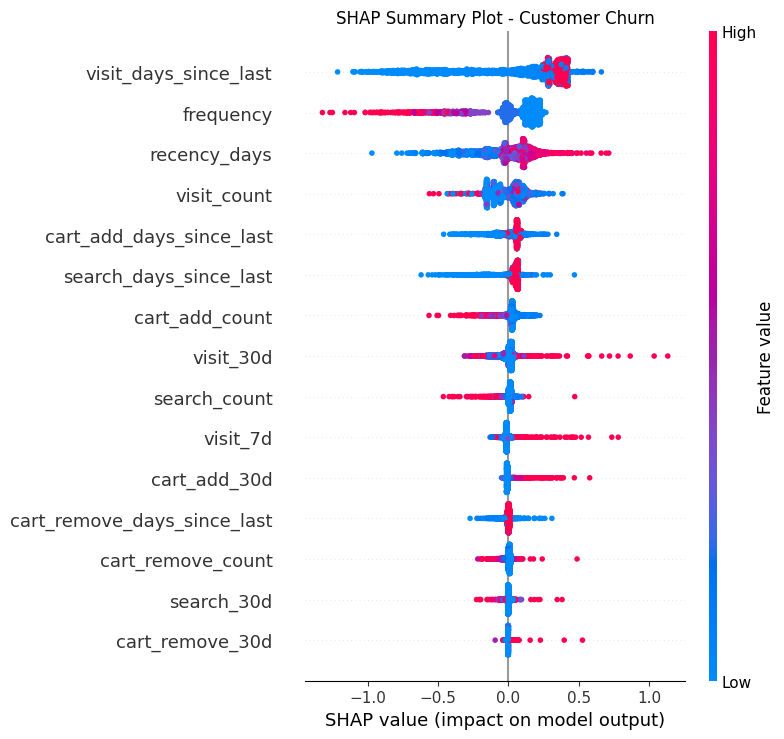

In [20]:
import shap
import matplotlib.pyplot as plt

shap.summary_plot(
    shap_values_churn,
    X_shap,
    max_display=15,
    show=False
)

plt.title("SHAP Summary Plot - Customer Churn")
plt.tight_layout()
plt.show()

In [21]:
import duckdb
from pathlib import Path

BASE = Path("/content/drive/MyDrive/Synerise/churn_experiment")
PROJECT = BASE / "purchase_prediction"

con = duckdb.connect()

files_to_check = {
    "product_buy": BASE / "input/product_buy.parquet",
    "train_target": BASE / "target/train_target.parquet",
    "validation_target": BASE / "target/validation_target.parquet",
}

for name, path in files_to_check.items():
    path_sql = path.as_posix().replace("'", "''")

    print(f"\n{'=' * 20} {name} {'=' * 20}")

    print("Columns:")
    print(con.execute(
        f"DESCRIBE SELECT * FROM read_parquet('{path_sql}')"
    ).fetchdf().to_string(index=False))

    print("\nDate range:")
    print(con.execute(f"""
        SELECT
            COUNT(*) AS rows_count,
            MIN(timestamp) AS first_timestamp,
            MAX(timestamp) AS last_timestamp
        FROM read_parquet('{path_sql}')
    """).fetchdf().to_string(index=False))


==================== product_buy ====================
Columns:
column_name  column_type null  key default extra
  client_id       BIGINT  YES None    None  None
  timestamp TIMESTAMP_NS  YES None    None  None
        sku       BIGINT  YES None    None  None

Date range:
 rows_count     first_timestamp      last_timestamp
    1789953 2022-06-23 00:12:15 2022-11-10 23:59:20

==================== train_target ====================
Columns:
column_name  column_type null  key default extra
  client_id       BIGINT  YES None    None  None
  timestamp TIMESTAMP_NS  YES None    None  None
        sku       BIGINT  YES None    None  None
   category       BIGINT  YES None    None  None
      price       BIGINT  YES None    None  None
       name      VARCHAR  YES None    None  None

Date range:
 rows_count     first_timestamp      last_timestamp
     254321 2022-11-11 00:00:40 2022-11-24 23:59:30

==================== validation_target ====================
Columns:
column_name  column_type nul

In [22]:
import duckdb

con = duckdb.connect()

base_path = BASE.as_posix().replace("'", "''")

query = f"""
WITH
train_buyers AS (
    SELECT DISTINCT client_id
    FROM read_parquet('{base_path}/input/product_buy.parquet')
    WHERE timestamp >= TIMESTAMP '2022-09-14 00:00:00'
      AND timestamp <  TIMESTAMP '2022-10-11 00:00:00'
),
validation_buyers AS (
    SELECT DISTINCT client_id
    FROM read_parquet('{base_path}/target/train_target.parquet')
    UNION
    SELECT DISTINCT client_id
    FROM read_parquet('{base_path}/target/validation_target.parquet')
),
prior_train_cohort AS (
    SELECT DISTINCT client_id
    FROM read_parquet('{base_path}/input/product_buy.parquet')
    WHERE timestamp < TIMESTAMP '2022-09-14 00:00:00'
),
prior_validation_cohort AS (
    SELECT DISTINCT client_id
    FROM read_parquet('{base_path}/input/product_buy.parquet')
    WHERE timestamp < TIMESTAMP '2022-11-11 00:00:00'
)
SELECT
    'Training window: Sep 14 - Oct 10' AS period,
    (SELECT COUNT(*) FROM prior_train_cohort) AS eligible_prior_buyers,
    (SELECT COUNT(*) FROM train_buyers) AS buyers_in_followup
UNION ALL
SELECT
    'Temporal test: Nov 11 - Dec 7',
    (SELECT COUNT(*) FROM prior_validation_cohort),
    (SELECT COUNT(*) FROM validation_buyers)
"""

print(con.execute(query).fetchdf().to_string(index=False))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

                          period  eligible_prior_buyers  buyers_in_followup
Training window: Sep 14 - Oct 10                 466099              174299
   Temporal test: Nov 11 - Dec 7                 750122              233841


In [23]:
import duckdb

con = duckdb.connect()
base_path = BASE.as_posix().replace("'", "''")

query = f"""
WITH
train_cohort AS (
    SELECT DISTINCT client_id
    FROM read_parquet('{base_path}/input/product_buy.parquet')
    WHERE timestamp < TIMESTAMP '2022-09-14 00:00:00'
),
train_followup AS (
    SELECT DISTINCT client_id
    FROM read_parquet('{base_path}/input/product_buy.parquet')
    WHERE timestamp >= TIMESTAMP '2022-09-14 00:00:00'
      AND timestamp <  TIMESTAMP '2022-10-11 00:00:00'
),
test_cohort AS (
    SELECT DISTINCT client_id
    FROM read_parquet('{base_path}/input/product_buy.parquet')
    WHERE timestamp < TIMESTAMP '2022-11-11 00:00:00'
),
test_followup AS (
    SELECT DISTINCT client_id
    FROM (
        SELECT client_id, timestamp
        FROM read_parquet('{base_path}/target/train_target.parquet')
        UNION ALL
        SELECT client_id, timestamp
        FROM read_parquet('{base_path}/target/validation_target.parquet')
    )
    WHERE timestamp >= TIMESTAMP '2022-11-11 00:00:00'
      AND timestamp <  TIMESTAMP '2022-12-08 00:00:00'
)
SELECT
    'Training' AS period,
    COUNT(*) AS eligible_customers,
    COUNT(*) FILTER (
        WHERE f.client_id IS NOT NULL
    ) AS customers_who_bought,
    COUNT(*) FILTER (
        WHERE f.client_id IS NULL
    ) AS customers_without_purchase
FROM train_cohort c
LEFT JOIN train_followup f USING (client_id)

UNION ALL

SELECT
    'Temporal test',
    COUNT(*),
    COUNT(*) FILTER (
        WHERE f.client_id IS NOT NULL
    ),
    COUNT(*) FILTER (
        WHERE f.client_id IS NULL
    )
FROM test_cohort c
LEFT JOIN test_followup f USING (client_id)
"""

print(con.execute(query).fetchdf().to_string(index=False))

       period  eligible_customers  customers_who_bought  customers_without_purchase
     Training              466099                 41190                      424909
Temporal test              750122                 74749                      675373


In [24]:
import duckdb

con = duckdb.connect()
base_path = BASE.as_posix().replace("'", "''")
output_path = (PROJECT / "churn_temporal_train.parquet").as_posix()

con.execute(f"""
COPY (
    WITH cohort AS (
        SELECT
            client_id,
            COUNT(*) AS frequency,
            DATE_DIFF(
                'day',
                CAST(MAX(timestamp) AS DATE),
                DATE '2022-09-13'
            ) AS recency_days
        FROM read_parquet('{base_path}/input/product_buy.parquet')
        WHERE timestamp < TIMESTAMP '2022-09-14 00:00:00'
        GROUP BY client_id
    ),
    followup AS (
        SELECT DISTINCT client_id
        FROM read_parquet('{base_path}/input/product_buy.parquet')
        WHERE timestamp >= TIMESTAMP '2022-09-14 00:00:00'
          AND timestamp <  TIMESTAMP '2022-10-11 00:00:00'
    )
    SELECT
        c.client_id,
        c.frequency,
        c.recency_days,
        CASE
            WHEN f.client_id IS NULL THEN 1
            ELSE 0
        END AS churn
    FROM cohort c
    LEFT JOIN followup f USING (client_id)
) TO '{output_path}' (FORMAT PARQUET)
""")

print(con.execute(f"""
    SELECT
        COUNT(*) AS customers,
        AVG(churn) AS churn_rate,
        MIN(recency_days) AS min_recency_days,
        MAX(recency_days) AS max_recency_days
    FROM read_parquet('{output_path}')
""").fetchdf().to_string(index=False))

 customers  churn_rate  min_recency_days  max_recency_days
    466099    0.911628                 0                82


In [25]:
import duckdb

con = duckdb.connect()
base_path = BASE.as_posix().replace("'", "''")
output_path = (PROJECT / "churn_temporal_test.parquet").as_posix()

con.execute(f"""
COPY (
    WITH cohort AS (
        SELECT
            client_id,
            COUNT(*) AS frequency,
            DATE_DIFF(
                'day',
                CAST(MAX(timestamp) AS DATE),
                DATE '2022-11-10'
            ) AS recency_days
        FROM read_parquet('{base_path}/input/product_buy.parquet')
        WHERE timestamp < TIMESTAMP '2022-11-11 00:00:00'
        GROUP BY client_id
    ),
    followup AS (
        SELECT DISTINCT client_id
        FROM (
            SELECT client_id, timestamp
            FROM read_parquet('{base_path}/target/train_target.parquet')
            UNION ALL
            SELECT client_id, timestamp
            FROM read_parquet('{base_path}/target/validation_target.parquet')
        )
        WHERE timestamp >= TIMESTAMP '2022-11-11 00:00:00'
          AND timestamp <  TIMESTAMP '2022-12-08 00:00:00'
    )
    SELECT
        c.client_id,
        c.frequency,
        c.recency_days,
        CASE
            WHEN f.client_id IS NULL THEN 1
            ELSE 0
        END AS churn
    FROM cohort c
    LEFT JOIN followup f USING (client_id)
) TO '{output_path}' (FORMAT PARQUET)
""")

print(con.execute(f"""
    SELECT
        COUNT(*) AS customers,
        AVG(churn) AS churn_rate,
        MIN(recency_days) AS min_recency_days,
        MAX(recency_days) AS max_recency_days
    FROM read_parquet('{output_path}')
""").fetchdf().to_string(index=False))

 customers  churn_rate  min_recency_days  max_recency_days
    750122    0.900351                 0               140


In [26]:
from pathlib import Path

print("PROJECT exists:", PROJECT.exists())
print("Input files:")
for name in [
    "product_buy.parquet",
    "add_to_cart.parquet",
    "remove_from_cart.parquet",
    "page_visit.parquet",
    "search_query.parquet",
]:
    p = BASE / "input" / name
    print(name, "->", p.exists())

PROJECT exists: True
Input files:
product_buy.parquet -> True
add_to_cart.parquet -> True
remove_from_cart.parquet -> True
page_visit.parquet -> True
search_query.parquet -> True


In [27]:

import duckdb

con = duckdb.connect()

for name in [
    "add_to_cart",
    "remove_from_cart",
    "page_visit",
    "search_query",
]:
    path = str(BASE / "input" / f"{name}.parquet")
    print(f"\n--- {name} ---")
    print(
        con.execute(
            "DESCRIBE SELECT * FROM read_parquet(?)",
            [path]
        ).fetchdf().to_string(index=False)
    )



--- add_to_cart ---
column_name  column_type null  key default extra
  client_id       BIGINT  YES None    None  None
  timestamp TIMESTAMP_NS  YES None    None  None
        sku       BIGINT  YES None    None  None

--- remove_from_cart ---
column_name  column_type null  key default extra
  client_id       BIGINT  YES None    None  None
  timestamp TIMESTAMP_NS  YES None    None  None
        sku       BIGINT  YES None    None  None

--- page_visit ---
column_name  column_type null  key default extra
  client_id       BIGINT  YES None    None  None
  timestamp TIMESTAMP_NS  YES None    None  None
        url       BIGINT  YES None    None  None

--- search_query ---
column_name  column_type null  key default extra
  client_id       BIGINT  YES None    None  None
  timestamp TIMESTAMP_NS  YES None    None  None
      query      VARCHAR  YES None    None  None


In [28]:

import duckdb
from pathlib import Path

con = duckdb.connect()
con.execute("SET memory_limit='8GB'")

cutoff = "2022-09-14"
lookback_start = "2022-06-23"
out_path = str(PROJECT / "churn_temporal_train_activity.parquet")

event_files = {
    "cart_add": str(BASE / "input" / "add_to_cart.parquet"),
    "cart_remove": str(BASE / "input" / "remove_from_cart.parquet"),
    "visit": str(BASE / "input" / "page_visit.parquet"),
    "search": str(BASE / "input" / "search_query.parquet"),
}

queries = []

for feature, path in event_files.items():
    queries.append(f"""
        SELECT
            client_id,
            '{feature}' AS event_type,
            timestamp
        FROM read_parquet('{path}')
        WHERE timestamp >= TIMESTAMP '{lookback_start}'
          AND timestamp < TIMESTAMP '{cutoff}'
    """)

events_sql = "\nUNION ALL\n".join(queries)

sql = f"""
COPY (
    WITH events AS (
        {events_sql}
    ),
    aggregated AS (
        SELECT
            client_id,

            COUNT(*) FILTER (WHERE event_type='cart_add') AS cart_add_count,
            COUNT(*) FILTER (
                WHERE event_type='cart_add'
                  AND timestamp >= TIMESTAMP '{cutoff}' - INTERVAL 7 DAY
            ) AS cart_add_7d,
            COUNT(*) FILTER (
                WHERE event_type='cart_add'
                  AND timestamp >= TIMESTAMP '{cutoff}' - INTERVAL 30 DAY
            ) AS cart_add_30d,
            DATE_DIFF('day',
                CAST(MAX(timestamp) FILTER (WHERE event_type='cart_add') AS DATE),
                DATE '{cutoff}' - INTERVAL 1 DAY
            ) AS cart_add_days_since_last,

            COUNT(*) FILTER (WHERE event_type='cart_remove') AS cart_remove_count,
            COUNT(*) FILTER (
                WHERE event_type='cart_remove'
                  AND timestamp >= TIMESTAMP '{cutoff}' - INTERVAL 7 DAY
            ) AS cart_remove_7d,
            COUNT(*) FILTER (
                WHERE event_type='cart_remove'
                  AND timestamp >= TIMESTAMP '{cutoff}' - INTERVAL 30 DAY
            ) AS cart_remove_30d,
            DATE_DIFF('day',
                CAST(MAX(timestamp) FILTER (WHERE event_type='cart_remove') AS DATE),
                DATE '{cutoff}' - INTERVAL 1 DAY
            ) AS cart_remove_days_since_last,

            COUNT(*) FILTER (WHERE event_type='visit') AS visit_count,
            COUNT(*) FILTER (
                WHERE event_type='visit'
                  AND timestamp >= TIMESTAMP '{cutoff}' - INTERVAL 7 DAY
            ) AS visit_7d,
            COUNT(*) FILTER (
                WHERE event_type='visit'
                  AND timestamp >= TIMESTAMP '{cutoff}' - INTERVAL 30 DAY
            ) AS visit_30d,
            DATE_DIFF('day',
                CAST(MAX(timestamp) FILTER (WHERE event_type='visit') AS DATE),
                DATE '{cutoff}' - INTERVAL 1 DAY
            ) AS visit_days_since_last,

            COUNT(*) FILTER (WHERE event_type='search') AS search_count,
            COUNT(*) FILTER (
                WHERE event_type='search'
                  AND timestamp >= TIMESTAMP '{cutoff}' - INTERVAL 7 DAY
            ) AS search_7d,
            COUNT(*) FILTER (
                WHERE event_type='search'
                  AND timestamp >= TIMESTAMP '{cutoff}' - INTERVAL 30 DAY
            ) AS search_30d,
            DATE_DIFF('day',
                CAST(MAX(timestamp) FILTER (WHERE event_type='search') AS DATE),
                DATE '{cutoff}' - INTERVAL 1 DAY
            ) AS search_days_since_last

        FROM events
        GROUP BY client_id
    )
    SELECT * FROM aggregated
) TO '{out_path}' (FORMAT PARQUET)
"""

con.execute(sql)

print("Saved:", out_path)
print("Rows:", con.execute(
    f"SELECT COUNT(*) FROM read_parquet('{out_path}')"
).fetchone()[0])
print(con.execute(
    f"SELECT * FROM read_parquet('{out_path}') LIMIT 5"
).fetchdf())


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Saved: /content/drive/MyDrive/Synerise/churn_experiment/purchase_prediction/churn_temporal_train_activity.parquet
Rows: 11676845
   client_id  cart_add_count  cart_add_7d  cart_add_30d  \
0   10522335               5            0             0   
1    4611762               5            0             1   
2   23345474               1            0             1   
3   15673788               2            0             1   
4   23826056               5            0             1   

   cart_add_days_since_last  cart_remove_count  cart_remove_7d  \
0                        38                  2               0   
1                        24                  0               0   
2                        22                  0               0   
3                        16                  1               0   
4                        22                  0               0   

   cart_remove_30d  cart_remove_days_since_last  visit_count  visit_7d  \
0                0                           

In [29]:
import duckdb

con = duckdb.connect()

train_path = str(PROJECT / "churn_temporal_train.parquet")
activity_path = str(PROJECT / "churn_temporal_train_activity.parquet")
out_path = str(PROJECT / "churn_temporal_train_full.parquet")

con.execute(f"""
COPY (
    SELECT
        t.*,
        COALESCE(a.cart_add_count, 0) AS cart_add_count,
        COALESCE(a.cart_add_7d, 0) AS cart_add_7d,
        COALESCE(a.cart_add_30d, 0) AS cart_add_30d,
        COALESCE(a.cart_add_days_since_last, 999) AS cart_add_days_since_last,

        COALESCE(a.cart_remove_count, 0) AS cart_remove_count,
        COALESCE(a.cart_remove_7d, 0) AS cart_remove_7d,
        COALESCE(a.cart_remove_30d, 0) AS cart_remove_30d,
        COALESCE(a.cart_remove_days_since_last, 999) AS cart_remove_days_since_last,

        COALESCE(a.visit_count, 0) AS visit_count,
        COALESCE(a.visit_7d, 0) AS visit_7d,
        COALESCE(a.visit_30d, 0) AS visit_30d,
        COALESCE(a.visit_days_since_last, 999) AS visit_days_since_last,

        COALESCE(a.search_count, 0) AS search_count,
        COALESCE(a.search_7d, 0) AS search_7d,
        COALESCE(a.search_30d, 0) AS search_30d,
        COALESCE(a.search_days_since_last, 999) AS search_days_since_last

    FROM read_parquet('{train_path}') t
    LEFT JOIN read_parquet('{activity_path}') a USING (client_id)
) TO '{out_path}' (FORMAT PARQUET)
""")

print("Saved:", out_path)
print(con.execute(f"""
    SELECT COUNT(*) AS customers,
           AVG(churn) AS churn_rate
    FROM read_parquet('{out_path}')
""").fetchdf())

Saved: /content/drive/MyDrive/Synerise/churn_experiment/purchase_prediction/churn_temporal_train_full.parquet
   customers  churn_rate
0     466099    0.911628


In [30]:

import duckdb

con = duckdb.connect()
con.execute("SET memory_limit='8GB'")

cutoff = "2022-11-11"
lookback_start = "2022-08-20"
out_path = str(PROJECT / "churn_temporal_test_activity.parquet")

event_files = {
    "cart_add": str(BASE / "input" / "add_to_cart.parquet"),
    "cart_remove": str(BASE / "input" / "remove_from_cart.parquet"),
    "visit": str(BASE / "input" / "page_visit.parquet"),
    "search": str(BASE / "input" / "search_query.parquet"),
}

queries = []
for feature, path in event_files.items():
    queries.append(f"""
        SELECT client_id, '{feature}' AS event_type, timestamp
        FROM read_parquet('{path}')
        WHERE timestamp >= TIMESTAMP '{lookback_start}'
          AND timestamp < TIMESTAMP '{cutoff}'
    """)

events_sql = "\nUNION ALL\n".join(queries)

sql = f"""
COPY (
    WITH events AS (
        {events_sql}
    ),
    aggregated AS (
        SELECT
            client_id,

            COUNT(*) FILTER (WHERE event_type='cart_add') AS cart_add_count,
            COUNT(*) FILTER (WHERE event_type='cart_add'
                AND timestamp >= TIMESTAMP '{cutoff}' - INTERVAL 7 DAY) AS cart_add_7d,
            COUNT(*) FILTER (WHERE event_type='cart_add'
                AND timestamp >= TIMESTAMP '{cutoff}' - INTERVAL 30 DAY) AS cart_add_30d,
            DATE_DIFF('day',
                CAST(MAX(timestamp) FILTER (WHERE event_type='cart_add') AS DATE),
                DATE '{cutoff}' - INTERVAL 1 DAY) AS cart_add_days_since_last,

            COUNT(*) FILTER (WHERE event_type='cart_remove') AS cart_remove_count,
            COUNT(*) FILTER (WHERE event_type='cart_remove'
                AND timestamp >= TIMESTAMP '{cutoff}' - INTERVAL 7 DAY) AS cart_remove_7d,
            COUNT(*) FILTER (WHERE event_type='cart_remove'
                AND timestamp >= TIMESTAMP '{cutoff}' - INTERVAL 30 DAY) AS cart_remove_30d,
            DATE_DIFF('day',
                CAST(MAX(timestamp) FILTER (WHERE event_type='cart_remove') AS DATE),
                DATE '{cutoff}' - INTERVAL 1 DAY) AS cart_remove_days_since_last,

            COUNT(*) FILTER (WHERE event_type='visit') AS visit_count,
            COUNT(*) FILTER (WHERE event_type='visit'
                AND timestamp >= TIMESTAMP '{cutoff}' - INTERVAL 7 DAY) AS visit_7d,
            COUNT(*) FILTER (WHERE event_type='visit'
                AND timestamp >= TIMESTAMP '{cutoff}' - INTERVAL 30 DAY) AS visit_30d,
            DATE_DIFF('day',
                CAST(MAX(timestamp) FILTER (WHERE event_type='visit') AS DATE),
                DATE '{cutoff}' - INTERVAL 1 DAY) AS visit_days_since_last,

            COUNT(*) FILTER (WHERE event_type='search') AS search_count,
            COUNT(*) FILTER (WHERE event_type='search'
                AND timestamp >= TIMESTAMP '{cutoff}' - INTERVAL 7 DAY) AS search_7d,
            COUNT(*) FILTER (WHERE event_type='search'
                AND timestamp >= TIMESTAMP '{cutoff}' - INTERVAL 30 DAY) AS search_30d,
            DATE_DIFF('day',
                CAST(MAX(timestamp) FILTER (WHERE event_type='search') AS DATE),
                DATE '{cutoff}' - INTERVAL 1 DAY) AS search_days_since_last

        FROM events
        GROUP BY client_id
    )
    SELECT * FROM aggregated
) TO '{out_path}' (FORMAT PARQUET)
"""

con.execute(sql)

print("Saved:", out_path)
print("Rows:", con.execute(
    f"SELECT COUNT(*) FROM read_parquet('{out_path}')"
).fetchone()[0])


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Saved: /content/drive/MyDrive/Synerise/churn_experiment/purchase_prediction/churn_temporal_test_activity.parquet
Rows: 12245851


In [31]:

import duckdb

con = duckdb.connect()

test_path = str(PROJECT / "churn_temporal_test.parquet")
activity_path = str(PROJECT / "churn_temporal_test_activity.parquet")
out_path = str(PROJECT / "churn_temporal_test_full.parquet")

con.execute(f"""
COPY (
    SELECT
        t.*,
        COALESCE(a.cart_add_count, 0) AS cart_add_count,
        COALESCE(a.cart_add_7d, 0) AS cart_add_7d,
        COALESCE(a.cart_add_30d, 0) AS cart_add_30d,
        COALESCE(a.cart_add_days_since_last, 999) AS cart_add_days_since_last,

        COALESCE(a.cart_remove_count, 0) AS cart_remove_count,
        COALESCE(a.cart_remove_7d, 0) AS cart_remove_7d,
        COALESCE(a.cart_remove_30d, 0) AS cart_remove_30d,
        COALESCE(a.cart_remove_days_since_last, 999) AS cart_remove_days_since_last,

        COALESCE(a.visit_count, 0) AS visit_count,
        COALESCE(a.visit_7d, 0) AS visit_7d,
        COALESCE(a.visit_30d, 0) AS visit_30d,
        COALESCE(a.visit_days_since_last, 999) AS visit_days_since_last,

        COALESCE(a.search_count, 0) AS search_count,
        COALESCE(a.search_7d, 0) AS search_7d,
        COALESCE(a.search_30d, 0) AS search_30d,
        COALESCE(a.search_days_since_last, 999) AS search_days_since_last

    FROM read_parquet('{test_path}') t
    LEFT JOIN read_parquet('{activity_path}') a USING (client_id)
) TO '{out_path}' (FORMAT PARQUET)
""")

print("Saved:", out_path)
print(con.execute(f"""
    SELECT COUNT(*) AS customers,
           AVG(churn) AS churn_rate
    FROM read_parquet('{out_path}')
""").fetchdf())


Saved: /content/drive/MyDrive/Synerise/churn_experiment/purchase_prediction/churn_temporal_test_full.parquet
   customers  churn_rate
0     750122    0.900351


In [32]:

import duckdb
import pandas as pd
import lightgbm as lgb

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
)

con = duckdb.connect()

train_path = str(PROJECT / "churn_temporal_train_full.parquet")
test_path = str(PROJECT / "churn_temporal_test_full.parquet")

train_df = con.execute(
    f"SELECT * FROM read_parquet('{train_path}')"
).fetchdf()

test_df = con.execute(
    f"SELECT * FROM read_parquet('{test_path}')"
).fetchdf()

target = "churn"

excluded = {"client_id", "churn", "purchases_with_sku"}
features = [
    c for c in train_df.columns
    if c not in excluded and c in test_df.columns
]

X_train = train_df[features].fillna(999)
y_train = train_df[target].astype(int)

X_test = test_df[features].fillna(999)
y_test = test_df[target].astype(int)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("Features:", features)

model_temporal = lgb.LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    class_weight="balanced",
    random_state=42,
    verbosity=-1,
)

model_temporal.fit(X_train, y_train)

proba = model_temporal.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print("\n--- Temporal Validation Results ---")
print(f"ROC-AUC:  {roc_auc_score(y_test, proba):.4f}")
print(f"PR-AUC:   {average_precision_score(y_test, proba):.4f}")
print(f"Precision (churn): {precision_score(y_test, pred, zero_division=0):.4f}")
print(f"Recall (churn):    {recall_score(y_test, pred, zero_division=0):.4f}")
print(f"F1 (churn):        {f1_score(y_test, pred, zero_division=0):.4f}")

print("\nClassification report:")
print(classification_report(
    y_test, pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))


Train shape: (466099, 18)
Test shape: (750122, 18)
Features: ['frequency', 'recency_days', 'cart_add_count', 'cart_add_7d', 'cart_add_30d', 'cart_add_days_since_last', 'cart_remove_count', 'cart_remove_7d', 'cart_remove_30d', 'cart_remove_days_since_last', 'visit_count', 'visit_7d', 'visit_30d', 'visit_days_since_last', 'search_count', 'search_7d', 'search_30d', 'search_days_since_last']

--- Temporal Validation Results ---
ROC-AUC:  0.7342
PR-AUC:   0.9511
Precision (churn): 0.9445
Recall (churn):    0.7598
F1 (churn):        0.8422

Classification report:
              precision    recall  f1-score   support

    No Churn       0.22      0.60      0.32     74749
       Churn       0.94      0.76      0.84    675373

    accuracy                           0.74    750122
   macro avg       0.58      0.68      0.58    750122
weighted avg       0.87      0.74      0.79    750122



In [33]:

import pandas as pd

# اختيار 10 عملاء عشوائيًا من بيانات الاختبار
sample = test_df.sample(n=10, random_state=42).copy()

# حساب احتمال الـ Churn
sample["churn_probability"] = model_temporal.predict_proba(
    sample[features]
)[:, 1]

# تحويل الاحتمال إلى توقع باستخدام threshold = 0.3
sample["predicted_churn"] = (
    sample["churn_probability"] >= 0.3
).astype(int)

# توضيح النتيجة بدل الأرقام
sample["predicted_label"] = sample["predicted_churn"].map({
    0: "No Churn",
    1: "Churn"
})

sample["actual_label"] = sample["churn"].map({
    0: "No Churn",
    1: "Churn"
})

sample["correct_prediction"] = (
    sample["predicted_churn"] == sample["churn"]
)

display(
    sample[[
        "client_id",
        "churn_probability",
        "predicted_label",
        "actual_label",
        "correct_prediction"
    ]].round({"churn_probability": 3})
)


,client_id,churn_probability,predicted_label,actual_label,correct_prediction
335900,3782645,0.555,Churn,Churn,True
375776,8180276,0.545,Churn,No Churn,False
358737,21228637,0.673,Churn,Churn,True
697368,12921087,0.718,Churn,Churn,True
213830,511460,0.646,Churn,Churn,True
383387,2340478,0.289,No Churn,Churn,False
383055,14561143,0.689,Churn,Churn,True
735294,20889150,0.407,Churn,No Churn,False
239895,8617127,0.378,Churn,Churn,True
595473,18629209,0.718,Churn,Churn,True


In [34]:

# اختيار 5 عملاء من كل فئة فعلية
sample_no_churn = test_df[test_df["churn"] == 0].sample(
    n=5, random_state=42
)
sample_churn = test_df[test_df["churn"] == 1].sample(
    n=5, random_state=42
)

sample = pd.concat(
    [sample_no_churn, sample_churn]
).sample(frac=1, random_state=42).copy()

sample["churn_probability"] = model_temporal.predict_proba(
    sample[features]
)[:, 1]

sample["predicted_label"] = (
    sample["churn_probability"] >= 0.3
).map({True: "Churn", False: "No Churn"})

sample["actual_label"] = sample["churn"].map({
    0: "No Churn",
    1: "Churn"
})

sample["correct_prediction"] = (
    sample["predicted_label"] == sample["actual_label"]
)

display(sample[[
    "client_id",
    "churn_probability",
    "predicted_label",
    "actual_label",
    "correct_prediction"
]].round({"churn_probability": 3}))


,client_id,churn_probability,predicted_label,actual_label,correct_prediction
451371,23605526,0.472,Churn,Churn,True
206722,14814361,0.295,No Churn,No Churn,True
594586,14596906,0.749,Churn,Churn,True
315597,15268464,0.558,Churn,No Churn,False
577298,8894337,0.718,Churn,Churn,True
41581,18225576,0.099,No Churn,No Churn,True
354422,13722546,0.716,Churn,Churn,True
345030,18740840,0.443,Churn,No Churn,False
37844,1457009,0.287,No Churn,No Churn,True
342038,18483113,0.707,Churn,Churn,True


In [35]:

# ترتيب العملاء من الأعلى إلى الأقل في احتمال الـ Churn
results = test_df[["client_id", "churn"]].copy()

results["churn_probability"] = model_temporal.predict_proba(
    test_df[features]
)[:, 1]

results["predicted_churn"] = (
    results["churn_probability"] >= 0.3
).astype(int)

# أعلى 20 عميلًا في احتمال الـ Churn
top_20 = results.sort_values(
    "churn_probability", ascending=False
).head(20).copy()

top_20["actual_label"] = top_20["churn"].map({
    0: "No Churn",
    1: "Churn"
})

display(top_20[[
    "client_id",
    "churn_probability",
    "predicted_churn",
    "actual_label"
]].round({"churn_probability": 3}))


,client_id,churn_probability,predicted_churn,actual_label
359937,2535802,0.980,1,Churn
94751,14465342,0.977,1,Churn
217230,7579286,0.972,1,Churn
52783,9793030,0.972,1,Churn
281993,13891173,0.970,1,Churn
94971,14968925,0.970,1,Churn
149449,22967362,0.966,1,Churn
127753,5257991,0.964,1,Churn
106222,3549477,0.961,1,Churn
212612,3099484,0.960,1,Churn


In [36]:
top10_ids = top_20.head(10)["client_id"].tolist()

customer_details = test_df[
    test_df["client_id"].isin(top10_ids)
].copy()

customer_details["churn_probability"] = model_temporal.predict_proba(
    customer_details[features]
)[:, 1]

customer_details["predicted_churn"] = (
    customer_details["churn_probability"] >= 0.3
).astype(int)

customer_details["actual_status"] = customer_details["churn"].map({
    1: "Churn",
    0: "No Churn"
})

display(
    customer_details[[
        "client_id",
        "churn_probability",
        "predicted_churn",
        "actual_status",
        "frequency",
        "recency_days",
        "visit_days_since_last",
        "visit_count",
        "cart_add_count",
        "search_count"
    ]]
    .sort_values("churn_probability", ascending=False)
    .round(3)
    .reset_index(drop=True)
)

,client_id,churn_probability,predicted_churn,actual_status,frequency,recency_days,visit_days_since_last,visit_count,cart_add_count,search_count
0,2535802,0.980,1,Churn,3,82,81,80,25,1
1,14465342,0.977,1,Churn,2,82,72,196,16,1
2,7579286,0.972,1,Churn,2,82,82,68,7,10
3,9793030,0.972,1,Churn,13,81,58,195,15,2
4,13891173,0.970,1,Churn,4,78,78,114,18,4
5,14968925,0.970,1,Churn,4,81,79,142,29,10
6,22967362,0.966,1,Churn,1,77,77,77,18,0
7,5257991,0.964,1,Churn,43,87,75,179,27,9
8,3549477,0.961,1,Churn,15,82,53,116,18,4
9,3099484,0.960,1,Churn,2,81,81,68,7,0


In [37]:
cols = [
    "client_id",
    "churn_probability",
    "predicted_churn",
    "actual_status",
    "frequency",
    "recency_days",
    "visit_days_since_last",
    "visit_count",
    "cart_add_count",
    "search_count"
]

customer_details[cols].sort_values(
    "churn_probability", ascending=False
).head(10).to_string(index=False)

' client_id  churn_probability  predicted_churn actual_status  frequency  recency_days  visit_days_since_last  visit_count  cart_add_count  search_count\n   2535802           0.980059                1         Churn          3            82                     81           80              25             1\n  14465342           0.976503                1         Churn          2            82                     72          196              16             1\n   7579286           0.971990                1         Churn          2            82                     82           68               7            10\n   9793030           0.971854                1         Churn         13            81                     58          195              15             2\n  13891173           0.970320                1         Churn          4            78                     78          114              18             4\n  14968925           0.969982                1         Churn          4          

In [38]:
import pandas as pd

importance_df = pd.DataFrame({
    "feature": features,
    "importance": model_temporal.feature_importances_
}).sort_values("importance", ascending=False)

display(importance_df)

,feature,importance
10,visit_count,1994
1,recency_days,1548
12,visit_30d,1415
13,visit_days_since_last,1398
5,cart_add_days_since_last,1182
14,search_count,980
0,frequency,952
2,cart_add_count,946
17,search_days_since_last,870
9,cart_remove_days_since_last,718


/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


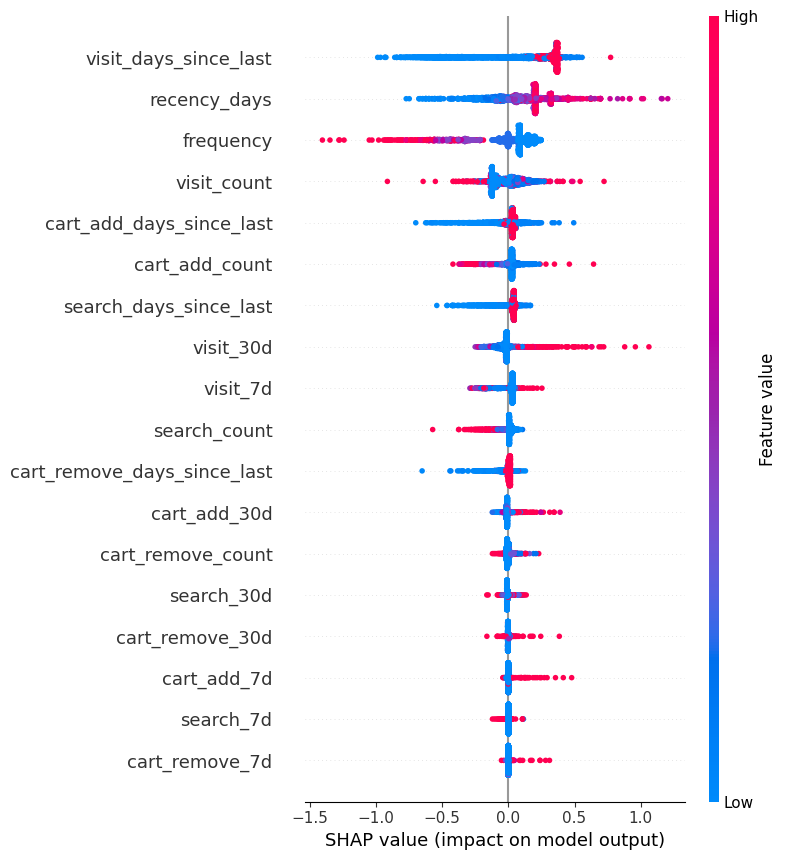

In [39]:
import shap

# عينة عشوائية من بيانات الاختبار
X_sample = X_test.sample(
    n=min(2000, len(X_test)),
    random_state=42
)

# حساب SHAP
explainer = shap.TreeExplainer(model_temporal)
shap_values = explainer.shap_values(X_sample)

# رسم أهم الخصائص وتأثيرها
shap.summary_plot(shap_values, X_sample)

In [40]:
print("Model:", type(model_temporal).__name__)
print("Number of features:", len(features))
print("Features used:")
print(features)

print("\nTarget accidentally included?",
      "churn" in features)

print("Client ID included?",
      "client_id" in features)

print("Duplicate features?",
      len(features) != len(set(features)))

print("\nTrain shape:", X_train.shape)
print("Test shape:", X_test.shape)

Model: LGBMClassifier
Number of features: 18
Features used:
['frequency', 'recency_days', 'cart_add_count', 'cart_add_7d', 'cart_add_30d', 'cart_add_days_since_last', 'cart_remove_count', 'cart_remove_7d', 'cart_remove_30d', 'cart_remove_days_since_last', 'visit_count', 'visit_7d', 'visit_30d', 'visit_days_since_last', 'search_count', 'search_7d', 'search_30d', 'search_days_since_last']

Target accidentally included? False
Client ID included? False
Duplicate features? False

Train shape: (466099, 18)
Test shape: (750122, 18)


In [41]:
print("TRAIN")
print("Rows:", len(train_df))
print("Duplicate clients:", train_df["client_id"].duplicated().sum())
print("Missing churn labels:", train_df["churn"].isna().sum())
print("Churn rate:", round(train_df["churn"].mean(), 4))

print("\nTEST")
print("Rows:", len(test_df))
print("Duplicate clients:", test_df["client_id"].duplicated().sum())
print("Missing churn labels:", test_df["churn"].isna().sum())
print("Churn rate:", round(test_df["churn"].mean(), 4))

TRAIN
Rows: 466099
Duplicate clients: 0
Missing churn labels: 0
Churn rate: 0.9116

TEST
Rows: 750122
Duplicate clients: 0
Missing churn labels: 0
Churn rate: 0.9004


In [42]:
import duckdb

con = duckdb.connect()

for name, path in [
    ("TRAIN TARGET", str(BASE / "target/train_target.parquet")),
    ("VALIDATION TARGET", str(BASE / "target/validation_target.parquet"))
]:
    print(f"\n{name}")

    result = con.execute("""
        SELECT
            MIN(timestamp) AS first_event,
            MAX(timestamp) AS last_event,
            COUNT(*) AS total_events,
            COUNT(DISTINCT client_id) AS unique_clients
        FROM read_parquet(?)
    """, [path]).df()

    print(result.to_string(index=False))


TRAIN TARGET
        first_event          last_event  total_events  unique_clients
2022-11-11 00:00:40 2022-11-24 23:59:30        254321          119236

VALIDATION TARGET
        first_event          last_event  total_events  unique_clients
2022-11-25 00:00:15 2022-12-08 00:09:15        274228          130466


In [43]:
print("TRAIN columns:")
print(train_df.columns.tolist())

print("\nTEST columns:")
print(test_df.columns.tolist())

print("\nTrain sample:")
display(train_df[["client_id", "churn"] + features[:4]].head())

print("\nTest sample:")
display(test_df[["client_id", "churn"] + features[:4]].head())

TRAIN columns:
['client_id', 'frequency', 'recency_days', 'churn', 'cart_add_count', 'cart_add_7d', 'cart_add_30d', 'cart_add_days_since_last', 'cart_remove_count', 'cart_remove_7d', 'cart_remove_30d', 'cart_remove_days_since_last', 'visit_count', 'visit_7d', 'visit_30d', 'visit_days_since_last', 'search_count', 'search_7d', 'search_30d', 'search_days_since_last']

TEST columns:
['client_id', 'frequency', 'recency_days', 'churn', 'cart_add_count', 'cart_add_7d', 'cart_add_30d', 'cart_add_days_since_last', 'cart_remove_count', 'cart_remove_7d', 'cart_remove_30d', 'cart_remove_days_since_last', 'visit_count', 'visit_7d', 'visit_30d', 'visit_days_since_last', 'search_count', 'search_7d', 'search_30d', 'search_days_since_last']

Train sample:


,client_id,churn,frequency,recency_days,cart_add_count,cart_add_7d
0,7064175,0,17,17,22,12
1,21143567,1,1,10,1,0
2,3908096,1,1,1,2,2
3,14142284,1,1,30,1,0
4,1575153,1,1,8,1,0



Test sample:


,client_id,churn,frequency,recency_days,cart_add_count,cart_add_7d
0,13050178,1,4,15,6,0
1,6558459,1,2,9,1,0
2,10123678,1,3,67,2,0
3,15887462,1,1,47,2,0
4,7660806,1,5,37,9,0


In [44]:
from pathlib import Path
import duckdb

con = duckdb.connect()

files_to_check = [
    PROJECT / "churn_temporal_train_full.parquet",
    PROJECT / "churn_temporal_test_full.parquet",
    PROJECT / "churn_temporal_train_activity.parquet",
    PROJECT / "churn_temporal_test_activity.parquet",
]

for path in files_to_check:
    print(f"\n--- {path.name} ---")
    if path.exists():
        print(
            con.execute(
                "DESCRIBE SELECT * FROM read_parquet(?)",
                [str(path)]
            ).df()[["column_name", "column_type"]].to_string(index=False)
        )
    else:
        print("File not found")


--- churn_temporal_train_full.parquet ---
                column_name column_type
                  client_id      BIGINT
                  frequency      BIGINT
               recency_days      BIGINT
                      churn     INTEGER
             cart_add_count      BIGINT
                cart_add_7d      BIGINT
               cart_add_30d      BIGINT
   cart_add_days_since_last      BIGINT
          cart_remove_count      BIGINT
             cart_remove_7d      BIGINT
            cart_remove_30d      BIGINT
cart_remove_days_since_last      BIGINT
                visit_count      BIGINT
                   visit_7d      BIGINT
                  visit_30d      BIGINT
      visit_days_since_last      BIGINT
               search_count      BIGINT
                  search_7d      BIGINT
                 search_30d      BIGINT
     search_days_since_last      BIGINT

--- churn_temporal_test_full.parquet ---
                column_name column_type
                  client_id      BI

In [45]:
import duckdb

con = duckdb.connect()

test_path = str(PROJECT / "churn_temporal_test_full.parquet")
train_target = str(BASE / "target/train_target.parquet")
valid_target = str(BASE / "target/validation_target.parquet")

result = con.execute("""
WITH actual AS (
    SELECT DISTINCT client_id
    FROM read_parquet(?)
    UNION
    SELECT DISTINCT client_id
    FROM read_parquet(?)
),
check_labels AS (
    SELECT
        t.client_id,
        t.churn,
        CASE WHEN a.client_id IS NOT NULL THEN 0 ELSE 1 END AS expected_churn
    FROM read_parquet(?) t
    LEFT JOIN actual a USING (client_id)
)
SELECT
    COUNT(*) AS total_clients,
    SUM(CASE WHEN churn = expected_churn THEN 1 ELSE 0 END) AS matching_labels,
    SUM(CASE WHEN churn != expected_churn THEN 1 ELSE 0 END) AS mismatched_labels
FROM check_labels
""", [train_target, valid_target, test_path]).fetchdf()

display(result)

,total_clients,matching_labels,mismatched_labels
0,750122,750118.0,4.0


In [46]:
print("Test rows:", len(test_df))
print("Target columns:", con.execute("""
DESCRIBE SELECT * FROM read_parquet(?)
""", [str(BASE / "target/train_target.parquet")]).fetchdf()["column_name"].tolist())

Test rows: 750122
Target columns: ['client_id', 'timestamp', 'sku', 'category', 'price', 'name']


In [47]:
import duckdb

test_path = str(PROJECT / "churn_temporal_test_full.parquet")
train_target = str(BASE / "target/train_target.parquet")
valid_target = str(BASE / "target/validation_target.parquet")

result = con.execute("""
WITH purchases AS (
    SELECT DISTINCT client_id
    FROM (
        SELECT client_id, timestamp
        FROM read_parquet(?)
        UNION ALL
        SELECT client_id, timestamp
        FROM read_parquet(?)
    )
    WHERE timestamp >= TIMESTAMP '2022-11-11'
      AND timestamp < TIMESTAMP '2022-12-08 00:10:00'
),
comparison AS (
    SELECT
        t.client_id,
        t.churn,
        CASE WHEN p.client_id IS NULL THEN 1 ELSE 0 END AS expected_churn
    FROM read_parquet(?) t
    LEFT JOIN purchases p USING (client_id)
)
SELECT
    COUNT(*) AS total_clients,
    SUM(CASE WHEN churn = expected_churn THEN 1 ELSE 0 END) AS matching_labels,
    SUM(CASE WHEN churn != expected_churn THEN 1 ELSE 0 END) AS mismatched_labels
FROM comparison
""", [train_target, valid_target, test_path]).fetchdf()

display(result)

,total_clients,matching_labels,mismatched_labels
0,750122,750118.0,4.0


In [48]:
import duckdb

test_path = str(PROJECT / "churn_temporal_test_full.parquet")

display(con.execute("""
SELECT
    COUNT(*) AS total_rows,
    COUNT(DISTINCT client_id) AS unique_clients,
    SUM(CASE WHEN churn = 1 THEN 1 ELSE 0 END) AS churn_clients,
    SUM(CASE WHEN churn = 0 THEN 1 ELSE 0 END) AS non_churn_clients,
    SUM(CASE WHEN churn IS NULL THEN 1 ELSE 0 END) AS missing_labels,
    MIN(churn) AS min_label,
    MAX(churn) AS max_label
FROM read_parquet(?)
""", [test_path]).fetchdf())

,total_rows,unique_clients,churn_clients,non_churn_clients,missing_labels,min_label,max_label
0,750122,750122,675373.0,74749.0,0.0,0,1


In [49]:

import duckdb
import pandas as pd
from pathlib import Path

db = duckdb.connect()
base = Path("/content/drive/MyDrive/Synerise/churn_experiment")
project = base / "purchase_prediction"

files = {
    "train": project / "churn_temporal_train_full.parquet",
    "test": project / "churn_temporal_test_full.parquet",
    "target_train": base / "target" / "train_target.parquet",
    "target_validation": base / "target" / "validation_target.parquet",
}

print("=" * 65)
print("1) FILE EXISTENCE")
print("=" * 65)
for name, path in files.items():
    print(f"{name}: {'OK' if path.exists() else 'MISSING'} | {path}")

missing_files = [name for name, path in files.items() if not path.exists()]
if missing_files:
    raise FileNotFoundError(f"Missing files: {missing_files}")

def pq(path):
    # Safely quote a path for DuckDB SQL
    return "'" + str(path).replace("'", "''") + "'"

print("\n" + "=" * 65)
print("2) TRAIN / TEST ROWS, IDS, LABELS, NULLS, DUPLICATES")
print("=" * 65)

for name in ("train", "test"):
    path = files[name]
    sql = f"""
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT client_id) AS unique_clients,
        COUNT(*) - COUNT(DISTINCT client_id) AS duplicate_rows_by_client,
        SUM(CASE WHEN churn = 1 THEN 1 ELSE 0 END) AS churn_rows,
        SUM(CASE WHEN churn = 0 THEN 1 ELSE 0 END) AS non_churn_rows,
        SUM(CASE WHEN churn IS NULL THEN 1 ELSE 0 END) AS missing_labels,
        MIN(churn) AS min_label,
        MAX(churn) AS max_label,
        SUM(CASE WHEN client_id IS NULL THEN 1 ELSE 0 END) AS missing_client_ids
    FROM read_parquet({pq(path)})
    """
    result = db.execute(sql).fetchdf()
    print(f"\n{name.upper()}")
    print(result.to_string(index=False))
    print("Columns:", db.execute(
        f"SELECT * FROM read_parquet({pq(path)}) LIMIT 0"
    ).fetchdf().columns.tolist())

print("\n" + "=" * 65)
print("3) TARGET FILE PERIODS AND UNIQUE CLIENTS")
print("=" * 65)

for name in ("target_train", "target_validation"):
    path = files[name]
    sql = f"""
    SELECT
        COUNT(*) AS purchase_events,
        COUNT(DISTINCT client_id) AS unique_purchasing_clients,
        COUNT(*) FILTER (WHERE client_id IS NULL) AS missing_client_ids,
        MIN(timestamp) AS first_event,
        MAX(timestamp) AS last_event
    FROM read_parquet({pq(path)})
    """
    print(f"\n{name.upper()}")
    print(db.execute(sql).fetchdf().to_string(index=False))

print("\n" + "=" * 65)
print("4) CHECK TEST LABELS AGAINST OBSERVED TARGET PURCHASES")
print("=" * 65)

# Combine the two target periods and identify every client who purchased.
target_union = f"""
    SELECT client_id FROM read_parquet({pq(files['target_train'])})
    WHERE client_id IS NOT NULL
    UNION
    SELECT client_id FROM read_parquet({pq(files['target_validation'])})
    WHERE client_id IS NOT NULL
"""

# Expected convention: churn=1 means no purchase in the target period;
# churn=0 means at least one purchase.
check_sql = f"""
WITH test_data AS (
    SELECT client_id, churn
    FROM read_parquet({pq(files['test'])})
),
purchasers AS (
    {target_union}
),
comparison AS (
    SELECT
        t.client_id,
        t.churn,
        CASE WHEN p.client_id IS NOT NULL THEN 1 ELSE 0 END AS purchased
    FROM test_data t
    LEFT JOIN purchasers p ON t.client_id = p.client_id
)
SELECT
    COUNT(*) AS test_rows,
    COUNT(DISTINCT client_id) AS unique_test_clients,
    SUM(CASE WHEN churn = 1 AND purchased = 0 THEN 1 ELSE 0 END)
        AS labels_matching_churn_definition,
    SUM(CASE WHEN churn = 0 AND purchased = 1 THEN 1 ELSE 0 END)
        AS labels_matching_active_definition,
    SUM(CASE WHEN churn = 1 AND purchased = 1 THEN 1 ELSE 0 END)
        AS churn_label_but_purchase_observed,
    SUM(CASE WHEN churn = 0 AND purchased = 0 THEN 1 ELSE 0 END)
        AS active_label_but_no_purchase_observed,
    SUM(CASE WHEN churn IS NULL THEN 1 ELSE 0 END) AS missing_labels
FROM comparison
"""
print(db.execute(check_sql).fetchdf().to_string(index=False))

print("\n" + "=" * 65)
print("5) CHECKS COMPLETE")
print("Reminder: the target periods must exactly match the test label window.")
print("=" * 65)


1) FILE EXISTENCE
train: OK | /content/drive/MyDrive/Synerise/churn_experiment/purchase_prediction/churn_temporal_train_full.parquet
test: OK | /content/drive/MyDrive/Synerise/churn_experiment/purchase_prediction/churn_temporal_test_full.parquet
target_train: OK | /content/drive/MyDrive/Synerise/churn_experiment/target/train_target.parquet
target_validation: OK | /content/drive/MyDrive/Synerise/churn_experiment/target/validation_target.parquet

2) TRAIN / TEST ROWS, IDS, LABELS, NULLS, DUPLICATES

TRAIN
 total_rows  unique_clients  duplicate_rows_by_client  churn_rows  non_churn_rows  missing_labels  min_label  max_label  missing_client_ids
     466099          466099                         0    424909.0         41190.0             0.0          0          1                 0.0
Columns: ['client_id', 'frequency', 'recency_days', 'churn', 'cart_add_count', 'cart_add_7d', 'cart_add_30d', 'cart_add_days_since_last', 'cart_remove_count', 'cart_remove_7d', 'cart_remove_30d', 'cart_remove_da

In [50]:

import duckdb
import pandas as pd
import numpy as np

con = duckdb.connect()

train_path = str(PROJECT / "churn_temporal_train_full.parquet")
test_path = str(PROJECT / "churn_temporal_test_full.parquet")

# Load the existing customer-level features
activity = con.execute("""
    SELECT *
    FROM read_parquet(?)
""", [train_path]).fetchdf()

print("Dataset shape:", activity.shape)
print("\nAvailable columns:")
print(activity.columns.tolist())

# RFM-style analysis using available Recency and Frequency.
# Monetary is not included because its availability has not been confirmed.
activity["activity_segment"] = np.select(
    [
        (activity["recency_days"] <= 7) & (activity["frequency"] >= 5),
        (activity["recency_days"] <= 30) & (activity["frequency"] >= 2),
        (activity["recency_days"] > 30),
    ],
    [
        "Highly active",
        "Moderately active",
        "Low recent activity",
    ],
    default="Other"
)

summary = (
    activity.groupby("activity_segment", dropna=False)
    .agg(
        customers=("client_id", "nunique"),
        avg_frequency=("frequency", "mean"),
        avg_recency_days=("recency_days", "mean"),
        churn_rate=("churn", "mean"),
    )
    .reset_index()
)

summary["customer_percentage"] = (
    summary["customers"] / summary["customers"].sum() * 100
).round(2)

summary["avg_frequency"] = summary["avg_frequency"].round(2)
summary["avg_recency_days"] = summary["avg_recency_days"].round(2)
summary["churn_rate"] = (summary["churn_rate"] * 100).round(2)

display(summary.sort_values("customers", ascending=False))


Dataset shape: (466099, 20)

Available columns:
['client_id', 'frequency', 'recency_days', 'churn', 'cart_add_count', 'cart_add_7d', 'cart_add_30d', 'cart_add_days_since_last', 'cart_remove_count', 'cart_remove_7d', 'cart_remove_30d', 'cart_remove_days_since_last', 'visit_count', 'visit_7d', 'visit_30d', 'visit_days_since_last', 'search_count', 'search_7d', 'search_30d', 'search_days_since_last']


,activity_segment,customers,avg_frequency,avg_recency_days,churn_rate,customer_percentage
1,Low recent activity,265064,1.77,56.09,93.59,56.87
3,Other,101910,1.00,14.40,92.61,21.86
2,Moderately active,92086,3.47,15.00,85.24,19.76
0,Highly active,7039,10.53,3.14,56.34,1.51


In [51]:

import duckdb
import pandas as pd

con = duckdb.connect()
train_path = str(PROJECT / "churn_temporal_train_full.parquet")

behavior = con.execute("""
    SELECT
        churn,
        COUNT(*) AS customers,
        AVG(frequency) AS avg_frequency,
        AVG(recency_days) AS avg_recency_days,
        AVG(visit_count) AS avg_visits,
        AVG(visit_7d) AS avg_visits_7d,
        AVG(visit_30d) AS avg_visits_30d,
        AVG(search_count) AS avg_searches,
        AVG(search_7d) AS avg_searches_7d,
        AVG(search_30d) AS avg_searches_30d,
        AVG(cart_add_count) AS avg_cart_adds,
        AVG(cart_add_7d) AS avg_cart_adds_7d,
        AVG(cart_add_30d) AS avg_cart_adds_30d,
        AVG(cart_remove_count) AS avg_cart_removes,
        AVG(cart_remove_30d) AS avg_cart_removes_30d
    FROM read_parquet(?)
    GROUP BY churn
    ORDER BY churn
""", [train_path]).fetchdf()

display(behavior.round(3))


,churn,customers,avg_frequency,avg_recency_days,avg_visits,avg_visits_7d,avg_visits_30d,avg_searches,avg_searches_7d,avg_searches_30d,avg_cart_adds,avg_cart_adds_7d,avg_cart_adds_30d,avg_cart_removes,avg_cart_removes_30d
0,0,41190,3.668,29.151,101.874,11.331,45.276,12.999,1.575,5.812,6.336,0.991,3.187,2.839,1.469
1,1,424909,1.915,38.918,35.130,2.805,14.106,3.160,0.276,1.251,1.977,0.199,0.819,0.729,0.313


In [52]:

display(behavior.set_index("churn").T)


churn,0,1
customers,41190.000000,424909.000000
avg_frequency,3.667953,1.915205
avg_recency_days,29.150765,38.918451
avg_visits,101.873634,35.129722
avg_visits_7d,11.331440,2.804796
avg_visits_30d,45.275747,14.106002
avg_searches,12.999490,3.159651
avg_searches_7d,1.574581,0.275541
avg_searches_30d,5.811629,1.251131
avg_cart_adds,6.335980,1.977037


In [53]:

print("Model exists:", "model_temporal" in globals())
print("Feature list exists:", "features" in globals())
print("PROJECT exists:", "PROJECT" in globals())

if "model_temporal" in globals():
    print("Model type:", type(model_temporal).__name__)

if "features" in globals():
    print("Number of model features:", len(features))
    print("Model features:", list(features))


Model exists: True
Feature list exists: True
PROJECT exists: True
Model type: LGBMClassifier
Number of model features: 18
Model features: ['frequency', 'recency_days', 'cart_add_count', 'cart_add_7d', 'cart_add_30d', 'cart_add_days_since_last', 'cart_remove_count', 'cart_remove_7d', 'cart_remove_30d', 'cart_remove_days_since_last', 'visit_count', 'visit_7d', 'visit_30d', 'visit_days_since_last', 'search_count', 'search_7d', 'search_30d', 'search_days_since_last']


In [54]:

import pandas as pd
import numpy as np
from IPython.display import display

# Load an existing test customer
test_path = str(PROJECT / "churn_temporal_test_full.parquet")
test_df = pd.read_parquet(test_path)

# Select one customer for a demo
customer = test_df.iloc[[0]].copy()

# Use the exact model feature order
X_customer = customer[features].astype(float)

# Churn prediction
churn_probability = float(model_temporal.predict_proba(X_customer)[0, 1])
churn_prediction = int(churn_probability >= 0.30)

# Activity segment (same initial rules used in our analysis)
frequency = float(customer["frequency"].iloc[0])
recency = float(customer["recency_days"].iloc[0])

if recency <= 7 and frequency >= 5:
    segment = "Highly active"
elif recency <= 30 and frequency >= 2:
    segment = "Moderately active"
elif recency > 30:
    segment = "Low recent activity"
else:
    segment = "Other"

# Behavior summary
row = customer.iloc[0]
visits = float(row["visit_count"])
searches = float(row["search_count"])
cart_adds = float(row["cart_add_count"])
cart_removes = float(row["cart_remove_count"])

if churn_prediction == 1:
    recommendation = (
        "Prioritize re-engagement; consider a personalized reminder "
        "or relevant offer."
    )
else:
    recommendation = (
        "Maintain engagement; consider relevant product recommendations "
        "and retention messaging."
    )

report = pd.DataFrame([{
    "client_id": row["client_id"],
    "churn_probability_pct": round(churn_probability * 100, 2),
    "churn_prediction": "Churn risk" if churn_prediction else "Lower churn risk",
    "activity_segment": segment,
    "frequency": frequency,
    "recency_days": recency,
    "visit_count": visits,
    "search_count": searches,
    "cart_add_count": cart_adds,
    "cart_remove_count": cart_removes,
    "recommendation": recommendation,
}])

display(report.T.rename(columns={0: "Customer report"}))


,Customer report
client_id,13050178
churn_probability_pct,24.6
churn_prediction,Lower churn risk
activity_segment,Moderately active
frequency,4.0
recency_days,15.0
visit_count,103.0
search_count,5.0
cart_add_count,6.0
cart_remove_count,4.0


In [55]:

import pandas as pd
from IPython.display import display

test_path = PROJECT / "churn_temporal_test_full.parquet"
test_df = pd.read_parquet(test_path)

# عرض عينة من 20 عميل
sample = test_df.sample(n=min(20, len(test_df)), random_state=42)

# عرض الـ ID وبعض الخصائص المهمة
display(
    sample[
        [
            "client_id",
            "frequency",
            "recency_days",
            "visit_count",
            "search_count",
            "cart_add_count",
            "churn",
        ]
    ].reset_index(drop=True)
)


,client_id,frequency,recency_days,visit_count,search_count,cart_add_count,churn
0,3782645,1,117,4,0,0,1
1,8180276,4,6,41,0,1,0
2,21228637,2,64,102,11,1,1
3,12921087,1,127,0,0,0,1
4,511460,2,41,1,1,1,1
5,2340478,1,57,22,10,2,1
6,14561143,2,71,132,0,2,1
7,20889150,2,0,0,0,0,0
8,8617127,2,132,54,0,5,1
9,18629209,1,134,0,0,0,1


In [56]:

import pandas as pd
from IPython.display import display

# Load test data
test_path = PROJECT / "churn_temporal_test_full.parquet"
test_df = pd.read_parquet(test_path)

# Enter the client ID you want to test
client_id_input = input("Enter client_id: ").strip()

# Find the customer
customer = test_df[
    test_df["client_id"].astype(str) == client_id_input
]

if customer.empty:
    print("Client ID not found in the test dataset. Please check the ID.")
else:
    customer = customer.iloc[[0]].copy()

    # Predict churn probability
    X_customer = customer[features].astype(float)
    churn_probability = float(
        model_temporal.predict_proba(X_customer)[0, 1]
    )

    # Use the same threshold as the previous evaluation
    threshold = 0.30
    churn_prediction = int(churn_probability >= threshold)

    row = customer.iloc[0]
    frequency = float(row["frequency"])
    recency = float(row["recency_days"])

    # Activity segmentation
    if recency <= 7 and frequency >= 5:
        segment = "Highly active"
    elif recency <= 30 and frequency >= 2:
        segment = "Moderately active"
    elif recency > 30:
        segment = "Low recent activity"
    else:
        segment = "Other"

    # Recommendation
    if churn_prediction == 1:
        recommendation = (
            "Prioritize re-engagement; consider a personalized "
            "reminder or relevant offer."
        )
    else:
        recommendation = (
            "Maintain engagement; consider relevant product "
            "recommendations and retention messaging."
        )

    # Build customer report
    report = pd.DataFrame([{
        "client_id": row["client_id"],
        "churn_probability_pct": round(churn_probability * 100, 2),
        "churn_prediction": (
            "Churn risk" if churn_prediction else "Lower churn risk"
        ),
        "actual_churn_label": int(row["churn"]),
        "activity_segment": segment,
        "frequency": frequency,
        "recency_days": recency,
        "visit_count": row["visit_count"],
        "search_count": row["search_count"],
        "cart_add_count": row["cart_add_count"],
        "cart_remove_count": row["cart_remove_count"],
        "recommendation": recommendation,
    }])

    display(report.T.rename(columns={0: "Customer report"}))


Enter client_id: 566173


,Customer report
client_id,566173
churn_probability_pct,85.64
churn_prediction,Churn risk
actual_churn_label,1
activity_segment,Low recent activity
frequency,2.0
recency_days,81.0
visit_count,12
search_count,0
cart_add_count,2


In [57]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Load the full test dataset
test_df = pd.read_parquet(
    PROJECT / "churn_temporal_test_full.parquet"
)

X_test = test_df[features].astype(float)
y_test = test_df["churn"].astype(int)

# Predict probabilities and classes
y_prob = model_temporal.predict_proba(X_test)[:, 1]
threshold = 0.30
y_pred = (y_prob >= threshold).astype(int)

# Evaluate on the full test set
metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC",
        "PR-AUC"
    ],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_prob),
        average_precision_score(y_test, y_prob)
    ]
})

display(metrics.round(4))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))


,Metric,Score
0,Accuracy,0.8711
1,Precision,0.9265
2,Recall,0.9307
3,F1-score,0.9286
4,ROC-AUC,0.7342
5,PR-AUC,0.9511


Confusion matrix:
[[ 24922  49827]
 [ 46831 628542]]


In [58]:

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)
import pandas as pd

train_df = pd.read_parquet(
    PROJECT / "churn_temporal_train_full.parquet"
)
test_df = pd.read_parquet(
    PROJECT / "churn_temporal_test_full.parquet"
)

def evaluate_split(df, split_name):
    X = df[features].astype(float)
    y = df["churn"].astype(int)

    prob = model_temporal.predict_proba(X)[:, 1]
    pred = (prob >= 0.30).astype(int)

    return {
        "Dataset": split_name,
        "ROC-AUC": roc_auc_score(y, prob),
        "PR-AUC": average_precision_score(y, prob),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "Accuracy": accuracy_score(y, pred)
    }

comparison = pd.DataFrame([
    evaluate_split(train_df, "Train"),
    evaluate_split(test_df, "Test")
])

display(comparison.round(4))


,Dataset,ROC-AUC,PR-AUC,Precision,Recall,F1,Accuracy
0,Train,0.7471,0.9617,0.9356,0.9413,0.9385,0.8875
1,Test,0.7342,0.9511,0.9265,0.9307,0.9286,0.8711


In [59]:

import pandas as pd
from IPython.display import display

# Load test data
test_path = PROJECT / "churn_temporal_test_full.parquet"
test_df = pd.read_parquet(test_path)

# Enter the client ID you want to test
client_id_input = input("Enter client_id: ").strip()

# Find the customer
customer = test_df[
    test_df["client_id"].astype(str) == client_id_input
]

if customer.empty:
    print("Client ID not found in the test dataset. Please check the ID.")
else:
    customer = customer.iloc[[0]].copy()

    # Predict churn probability
    X_customer = customer[features].astype(float)
    churn_probability = float(
        model_temporal.predict_proba(X_customer)[0, 1]
    )

    # Use the same threshold as the previous evaluation
    threshold = 0.30
    churn_prediction = int(churn_probability >= threshold)

    row = customer.iloc[0]
    frequency = float(row["frequency"])
    recency = float(row["recency_days"])

    # Activity segmentation
    if recency <= 7 and frequency >= 5:
        segment = "Highly active"
    elif recency <= 30 and frequency >= 2:
        segment = "Moderately active"
    elif recency > 30:
        segment = "Low recent activity"
    else:
        segment = "Other"

    # Recommendation
    if churn_prediction == 1:
        recommendation = (
            "Prioritize re-engagement; consider a personalized "
            "reminder or relevant offer."
        )
    else:
        recommendation = (
            "Maintain engagement; consider relevant product "
            "recommendations and retention messaging."
        )

    # Build customer report
    report = pd.DataFrame([{
        "client_id": row["client_id"],
        "churn_probability_pct": round(churn_probability * 100, 2),
        "churn_prediction": (
            "Churn risk" if churn_prediction else "Lower churn risk"
        ),
        "actual_churn_label": int(row["churn"]),
        "activity_segment": segment,
        "frequency": frequency,
        "recency_days": recency,
        "visit_count": row["visit_count"],
        "search_count": row["search_count"],
        "cart_add_count": row["cart_add_count"],
        "cart_remove_count": row["cart_remove_count"],
        "recommendation": recommendation,
    }])

    display(report.T.rename(columns={0: "Customer report"}))


Enter client_id: 12921087	


,Customer report
client_id,12921087
churn_probability_pct,71.76
churn_prediction,Churn risk
actual_churn_label,1
activity_segment,Low recent activity
frequency,1.0
recency_days,127.0
visit_count,0
search_count,0
cart_add_count,0


In [60]:

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display

# =========================
# 1. Predictions & Metrics
# =========================
THRESHOLD = 0.30

train_prob = model_temporal.predict_proba(X_train)[:, 1]
test_prob = model_temporal.predict_proba(X_test)[:, 1]

train_pred = (train_prob >= THRESHOLD).astype(int)
test_pred = (test_prob >= THRESHOLD).astype(int)

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix
)

def get_metrics(y, pred, prob):
    return {
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1-score": f1_score(y, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y, prob),
        "PR-AUC": average_precision_score(y, prob)
    }

train_metrics = get_metrics(y_train, train_pred, train_prob)
test_metrics = get_metrics(y_test, test_pred, test_prob)

# =========================
# 2. Dashboard Style
# =========================
NAVY = "#14213D"
BLUE = "#4361EE"
CYAN = "#4CC9F0"
PURPLE = "#7209B7"
GREEN = "#2EC4B6"
ORANGE = "#F4A261"
RED = "#E63946"
BG = "#F5F7FB"
TEXT = "#263238"

template = "plotly_white"

# =========================
# 3. KPI Cards
# =========================
fig_kpi = make_subplots(
    rows=1, cols=4,
    specs=[[{"type": "indicator"}] * 4],
    horizontal_spacing=0.06
)

kpis = [
    ("Accuracy", test_metrics["Accuracy"], BLUE),
    ("Precision", test_metrics["Precision"], PURPLE),
    ("Recall", test_metrics["Recall"], GREEN),
    ("F1-score", test_metrics["F1-score"], ORANGE)
]

for i, (name, value, color) in enumerate(kpis, start=1):
    fig_kpi.add_trace(
        go.Indicator(
            mode="number",
            value=value * 100,
            number={
                "suffix": "%",
                "valueformat": ".2f",
                "font": {"size": 30, "color": color}
            },
            title={
                "text": f"<b>{name}</b>",
                "font": {"size": 15, "color": NAVY}
            },
        ),
        row=1, col=i
    )

fig_kpi.update_layout(
    title={
        "text": "CUSTOMER CHURN MODEL | TEST PERFORMANCE",
        "x": 0.5,
        "font": {"size": 21, "color": NAVY}
    },
    height=220,
    paper_bgcolor=BG,
    plot_bgcolor=BG,
    margin=dict(l=20, r=20, t=65, b=15),
    font=dict(family="Arial")
)

fig_kpi.show()

# =========================
# 4. Train vs Test Metrics
# =========================
metric_names = list(train_metrics.keys())

comparison = pd.DataFrame({
    "Metric": metric_names * 2,
    "Score": (
        list(train_metrics.values()) +
        list(test_metrics.values())
    ),
    "Dataset": ["Train"] * len(metric_names) +
               ["Test"] * len(metric_names)
})

fig_compare = px.bar(
    comparison,
    x="Metric",
    y="Score",
    color="Dataset",
    barmode="group",
    color_discrete_map={
        "Train": PURPLE,
        "Test": CYAN
    },
    text=comparison["Score"].map(lambda x: f"{x:.3f}"),
    title="Training vs Test Performance",
    template=template
)

fig_compare.update_traces(
    textposition="outside",
    marker_line_width=0
)
fig_compare.update_yaxes(range=[0, 1.12], tickformat=".0%")
fig_compare.update_layout(
    height=470,
    paper_bgcolor=BG,
    plot_bgcolor="white",
    font=dict(family="Arial", color=TEXT),
    legend_title_text="Dataset",
    title_x=0.5
)
fig_compare.show()

# =========================
# 5. Confusion Matrix
# =========================
cm = confusion_matrix(y_test, test_pred, labels=[0, 1])

cm_labels = [
    ["TN", "FP"],
    ["FN", "TP"]
]

annotations = []
for i in range(2):
    for j in range(2):
        annotations.append(
            dict(
                x=j, y=i,
                text=f"<b>{cm_labels[i][j]}</b><br>{cm[i, j]:,}",
                showarrow=False,
                font=dict(size=18, color="white" if cm[i, j] > cm.max()/2 else NAVY)
            )
        )

fig_cm = go.Figure(
    data=go.Heatmap(
        z=cm,
        x=["Predicted: No Churn", "Predicted: Churn"],
        y=["Actual: No Churn", "Actual: Churn"],
        colorscale=[
            [0.0, "#EAF2FF"],
            [0.5, "#6C8CFF"],
            [1.0, "#14213D"]
        ],
        showscale=True,
        hovertemplate="Count: %{z:,}<extra></extra>"
    )
)

fig_cm.update_layout(
    title="Confusion Matrix — Test Dataset",
    title_x=0.5,
    annotations=annotations,
    height=440,
    template=template,
    paper_bgcolor=BG,
    plot_bgcolor="white",
    font=dict(family="Arial", color=TEXT)
)
fig_cm.update_yaxes(autorange="reversed")
fig_cm.show()

# =========================
# 6. Feature Importance
# =========================
importance = pd.DataFrame({
    "Feature": features,
    "Importance": model_temporal.feature_importances_
}).sort_values("Importance", ascending=True).tail(15)

fig_imp = px.bar(
    importance,
    x="Importance",
    y="Feature",
    orientation="h",
    color="Importance",
    color_continuous_scale=["#4CC9F0", "#4361EE", "#7209B7"],
    title="Top 15 Feature Importances",
    template=template
)

fig_imp.update_layout(
    height=600,
    title_x=0.5,
    paper_bgcolor=BG,
    plot_bgcolor="white",
    coloraxis_showscale=False,
    font=dict(family="Arial", color=TEXT),
    yaxis_title="Feature",
    xaxis_title="Importance"
)
fig_imp.show()

# =========================
# 7. Actual vs Predicted Churn
# =========================
actual_counts = pd.Series(y_test).map({
    0: "No Churn",
    1: "Churn"
}).value_counts()

pred_counts = pd.Series(test_pred).map({
    0: "No Churn",
    1: "Churn"
}).value_counts()

distribution = pd.DataFrame({
    "Class": ["No Churn", "Churn", "No Churn", "Churn"],
    "Count": [
        int(actual_counts.get("No Churn", 0)),
        int(actual_counts.get("Churn", 0)),
        int(pred_counts.get("No Churn", 0)),
        int(pred_counts.get("Churn", 0))
    ],
    "Type": ["Actual"] * 2 + ["Predicted"] * 2
})

fig_dist = px.bar(
    distribution,
    x="Class",
    y="Count",
    color="Type",
    barmode="group",
    color_discrete_map={
        "Actual": BLUE,
        "Predicted": ORANGE
    },
    text_auto=",",
    title="Actual vs Predicted Customer Classes",
    template=template
)

fig_dist.update_layout(
    height=430,
    title_x=0.5,
    paper_bgcolor=BG,
    plot_bgcolor="white",
    font=dict(family="Arial", color=TEXT)
)
fig_dist.show()

# =========================
# 8. Churn Probability Distribution
# =========================
prob_df = pd.DataFrame({
    "Churn Probability": test_prob
})

fig_prob = px.histogram(
    prob_df,
    x="Churn Probability",
    nbins=40,
    color_discrete_sequence=[BLUE],
    title="Distribution of Predicted Churn Probabilities",
    template=template
)

fig_prob.add_vline(
    x=THRESHOLD,
    line_dash="dash",
    line_color=RED,
    annotation_text=f"Threshold = {THRESHOLD}",
    annotation_position="top"
)

fig_prob.update_layout(
    height=430,
    title_x=0.5,
    paper_bgcolor=BG,
    plot_bgcolor="white",
    font=dict(family="Arial", color=TEXT),
    xaxis_title="Predicted Churn Probability",
    yaxis_title="Number of Customers"
)
fig_prob.show()

print("Dashboard generated successfully.")
print(f"Test customers: {len(y_test):,}")
print(f"Threshold used: {THRESHOLD}")


Dashboard generated successfully.
Test customers: 750,122
Threshold used: 0.3


In [61]:

import pandas as pd
from IPython.display import display

test_path = PROJECT / "churn_temporal_test_full.parquet"
test_df = pd.read_parquet(test_path)

# اختيار عينة عشوائية جديدة كل مرة
sample = test_df.sample(n=min(10, len(test_df)))

display(
    sample[
        [
            "client_id",
            "frequency",
            "recency_days",
            "visit_count",
            "search_count",
            "cart_add_count",
            "churn",
        ]
    ].reset_index(drop=True)
)


,client_id,frequency,recency_days,visit_count,search_count,cart_add_count,churn
0,12880531,1,129,4,0,0,1
1,11182371,1,45,18,6,4,1
2,21637922,2,123,3,0,0,1
3,5012857,1,27,0,0,0,1
4,12674997,1,24,28,0,1,1
5,15680043,1,122,74,0,0,1
6,19832666,1,40,10,0,1,1
7,16642249,2,3,83,17,7,0
8,9287264,1,78,0,0,0,1
9,11449360,1,34,0,0,0,1


In [62]:

import pandas as pd
from IPython.display import display

# Load test data
test_path = PROJECT / "churn_temporal_test_full.parquet"
test_df = pd.read_parquet(test_path)

# Enter the client ID you want to test
client_id_input = input("Enter client_id: ").strip()

# Find the customer
customer = test_df[
    test_df["client_id"].astype(str) == client_id_input
]

if customer.empty:
    print("Client ID not found in the test dataset. Please check the ID.")
else:
    customer = customer.iloc[[0]].copy()

    # Predict churn probability
    X_customer = customer[features].astype(float)
    churn_probability = float(
        model_temporal.predict_proba(X_customer)[0, 1]
    )

    # Use the same threshold as the previous evaluation
    threshold = 0.30
    churn_prediction = int(churn_probability >= threshold)

    row = customer.iloc[0]
    frequency = float(row["frequency"])
    recency = float(row["recency_days"])

    # Activity segmentation
    if recency <= 7 and frequency >= 5:
        segment = "Highly active"
    elif recency <= 30 and frequency >= 2:
        segment = "Moderately active"
    elif recency > 30:
        segment = "Low recent activity"
    else:
        segment = "Other"

    # Recommendation
    if churn_prediction == 1:
        recommendation = (
            "Prioritize re-engagement; consider a personalized "
            "reminder or relevant offer."
        )
    else:
        recommendation = (
            "Maintain engagement; consider relevant product "
            "recommendations and retention messaging."
        )

    # Build customer report
    report = pd.DataFrame([{
        "client_id": row["client_id"],
        "churn_probability_pct": round(churn_probability * 100, 2),
        "churn_prediction": (
            "Churn risk" if churn_prediction else "Lower churn risk"
        ),
        "actual_churn_label": int(row["churn"]),
        "activity_segment": segment,
        "frequency": frequency,
        "recency_days": recency,
        "visit_count": row["visit_count"],
        "search_count": row["search_count"],
        "cart_add_count": row["cart_add_count"],
        "cart_remove_count": row["cart_remove_count"],
        "recommendation": recommendation,
    }])

    display(report.T.rename(columns={0: "Customer report"}))


Enter client_id: 20889150	


,Customer report
client_id,20889150
churn_probability_pct,40.74
churn_prediction,Churn risk
actual_churn_label,0
activity_segment,Moderately active
frequency,2.0
recency_days,0.0
visit_count,0
search_count,0
cart_add_count,0


In [63]:

import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score

# Probabilities from the test dataset
test_prob = model_temporal.predict_proba(X_test)[:, 1]
y_true = y_test.to_numpy() if hasattr(y_test, "to_numpy") else y_test

results = []

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]:
    pred = (test_prob >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Churn_Predicted_%": round(pred.mean() * 100, 2),
        "False_Positive": int(((pred == 1) & (y_true == 0)).sum()),
        "False_Negative": int(((pred == 0) & (y_true == 1)).sum()),
        "Precision": round(precision_score(y_true, pred, zero_division=0), 4),
        "Recall": round(recall_score(y_true, pred, zero_division=0), 4),
        "F1": round(f1_score(y_true, pred, zero_division=0), 4)
    })

display(pd.DataFrame(results))


,Threshold,Churn_Predicted_%,False_Positive,False_Negative,Precision,Recall,F1
0,0.3,90.43,49827,46831,0.9265,0.9307,0.9286
1,0.4,83.20,40057,91322,0.9358,0.8648,0.8989
2,0.5,72.43,30169,162193,0.9445,0.7598,0.8422
3,0.6,57.22,20199,266351,0.9529,0.6056,0.7406
4,0.7,35.35,10368,420588,0.9609,0.3773,0.5418
5,0.8,1.12,360,667353,0.9570,0.0119,0.0235
6,0.9,0.05,18,675039,0.9489,0.0005,0.0010


In [64]:

import pandas as pd

check = test_df.loc[
    test_df["churn"].astype(int) == 0,
    ["client_id", "churn"]
].copy()

check["churn_probability_pct"] = (
    model_temporal.predict_proba(
        test_df.loc[check.index, features].astype(float)
    )[:, 1] * 100
).round(2)

check["prediction_at_30"] = (
    check["churn_probability_pct"] >= 30
).map({True: "Churn risk", False: "Lower churn risk"})

display(
    check.sort_values(
        "churn_probability_pct", ascending=False
    ).head(20)
)


,client_id,churn,churn_probability_pct,prediction_at_30
285420,15841860,0,95.64,Churn risk
137255,23797168,0,95.14,Churn risk
9261,11456955,0,94.69,Churn risk
122593,10430038,0,92.59,Churn risk
204968,6581884,0,92.41,Churn risk
357650,8462359,0,92.36,Churn risk
143132,23138719,0,92.20,Churn risk
100138,23358778,0,91.69,Churn risk
61855,3995930,0,91.53,Churn risk
185572,1996741,0,91.45,Churn risk


In [65]:

import pandas as pd
import numpy as np

# Predict on the test dataset
test_prob = model_temporal.predict_proba(
    test_df[features].astype(float)
)[:, 1]

audit = test_df[["client_id", "churn"] + features].copy()
audit["churn_probability"] = test_prob
audit["predicted_churn"] = (test_prob >= 0.30).astype(int)

# Actual non-churn customers incorrectly predicted as churn
false_positives = audit[
    (audit["churn"] == 0) &
    (audit["predicted_churn"] == 1)
].copy()

# Actual non-churn customers predicted correctly
true_negatives = audit[
    (audit["churn"] == 0) &
    (audit["predicted_churn"] == 0)
].copy()

print("Actual non-churn customers:", int((audit["churn"] == 0).sum()))
print("False positives:", len(false_positives))
print("Correctly identified non-churn:", len(true_negatives))

# Compare feature averages between the two groups
comparison = pd.DataFrame({
    "False positives": false_positives[features].mean(),
    "Correct non-churn": true_negatives[features].mean()
})

comparison["Difference"] = (
    comparison["False positives"] -
    comparison["Correct non-churn"]
)

display(
    comparison.reindex(
        comparison["Difference"].abs().sort_values(
            ascending=False
        ).index
    ).round(3)
)

print("\nHighest-confidence false positives:")
display(
    false_positives[
        ["client_id", "churn", "churn_probability"] + features[:6]
    ].sort_values(
        "churn_probability", ascending=False
    ).head(10)
)


Actual non-churn customers: 74749
False positives: 49827
Correctly identified non-churn: 24922


,False positives,Correct non-churn,Difference
cart_remove_days_since_last,747.874,223.794,524.081
search_days_since_last,681.696,166.858,514.838
cart_add_days_since_last,477.692,57.935,419.757
visit_days_since_last,324.795,35.969,288.826
visit_count,34.149,183.312,-149.164
visit_30d,13.351,81.881,-68.530
recency_days,56.114,20.069,36.046
search_count,3.332,27.552,-24.220
visit_7d,2.808,24.698,-21.891
cart_add_count,2.413,17.895,-15.482



Highest-confidence false positives:


,client_id,churn,churn_probability,frequency,recency_days,cart_add_count,cart_add_7d,cart_add_30d,cart_add_days_since_last
285420,15841860,0,0.956379,29,28,55,0,55,28
137255,23797168,0,0.951379,2,81,18,0,0,81
9261,11456955,0,0.946914,12,62,15,0,0,62
122593,10430038,0,0.925891,1,73,18,0,0,73
204968,6581884,0,0.924130,24,82,12,0,0,82
357650,8462359,0,0.923637,1,81,12,0,0,64
143132,23138719,0,0.921968,1,80,1,0,0,80
100138,23358778,0,0.916918,7,85,7,0,4,27
61855,3995930,0,0.915304,4,107,5,0,0,78
185572,1996741,0,0.914513,3,129,6,0,0,82


In [66]:

import pandas as pd
import numpy as np

# 1) قارن الـ features بين العملاء الحقيقيين وغير الحقيقيين في churn
cols = [
    "churn", "recency_days",
    "visit_days_since_last",
    "cart_add_days_since_last",
    "cart_remove_days_since_last",
    "search_days_since_last",
    "visit_count", "frequency"
]

display(
    test_df.groupby("churn")[cols[1:]]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

# 2) هل الـ churn label متوافق مع recency_days؟
test_df["recency_band"] = pd.cut(
    test_df["recency_days"],
    bins=[-np.inf, 7, 14, 30, 60, 90, 180, np.inf],
    labels=["0-7", "8-14", "15-30", "31-60", "61-90", "91-180", "180+"]
)

display(
    test_df.groupby("recency_band", observed=False)
    .agg(
        customers=("churn", "size"),
        churn_rate=("churn", "mean"),
        avg_frequency=("frequency", "mean")
    )
    .round(3)
)

# 3) اعرض أمثلة لعملاء recency عندهم عالي لكن الـ label = 0
display(
    test_df[
        (test_df["churn"] == 0) &
        (test_df["recency_days"] >= 60)
    ][[
        "client_id", "churn", "recency_days", "frequency",
        "visit_days_since_last", "cart_add_days_since_last",
        "cart_remove_days_since_last", "search_days_since_last"
    ]].head(20)
)


recency_days                       visit_days_since_last                 \
             count  mean median min  max                 count    mean median   
churn                                                                           
0            74749  44.1   32.0   0  140                 74749  228.50    9.0   
1           675373  65.8   64.0   0  140                675373  445.39   62.0   

                ... visit_count                          frequency        \
      min  max  ...       count   mean median min    max     count  mean   
churn           ...                                                        
0       0  999  ...       74749  83.88   29.0   0  24875     74749  4.63   
1       0  999  ...      675373  26.21    4.0   0  13440    675373  2.14   

                       
      median min  max  
churn                  
0        2.0   1  357  
1        1.0   1  644  

[2 rows x 35 columns]

,customers,churn_rate,avg_frequency
recency_band,,,
0-7,64930,0.787,3.907
8-14,42860,0.830,3.650
15-30,102659,0.852,2.948
31-60,162693,0.899,2.354
61-90,152425,0.934,2.046
91-180,224555,0.947,1.703
180+,0,NaN,NaN


,client_id,churn,recency_days,frequency,visit_days_since_last,cart_add_days_since_last,cart_remove_days_since_last,search_days_since_last
31,10218471,0,69,21,8,69,69,69
46,5446931,0,78,2,13,78,78,999
50,1608952,0,64,2,21,64,999,64
52,10772025,0,76,5,17,76,999,999
68,6986647,0,76,3,14,76,999,71
82,10023825,0,114,2,52,56,999,999
97,20916822,0,67,2,31,67,999,999
102,14130257,0,81,4,1,81,81,14
118,3138345,0,71,6,46,71,71,999
290,12809893,0,69,3,0,65,69,19


In [67]:

from pathlib import Path
import duckdb

con = duckdb.connect()

files = {
    "churn_train": PROJECT / "churn_temporal_train_full.parquet",
    "churn_test": PROJECT / "churn_temporal_test_full.parquet",
    "purchase_train": BASE / "target" / "train_target.parquet",
    "purchase_validation": BASE / "target" / "validation_target.parquet",
}

for name, path in files.items():
    print(f"\n--- {name} ---")
    print("Exists:", path.exists(), "| Path:", path)

    if not path.exists():
        continue

    schema = con.execute(
        f"DESCRIBE SELECT * FROM read_parquet('{path}')"
    ).fetchdf()
    print("Columns:", schema["column_name"].tolist())

    df = con.execute(
        f"SELECT * FROM read_parquet('{path}') LIMIT 5"
    ).fetchdf()
    display(df)



--- churn_train ---
Exists: True | Path: /content/drive/MyDrive/Synerise/churn_experiment/purchase_prediction/churn_temporal_train_full.parquet
Columns: ['client_id', 'frequency', 'recency_days', 'churn', 'cart_add_count', 'cart_add_7d', 'cart_add_30d', 'cart_add_days_since_last', 'cart_remove_count', 'cart_remove_7d', 'cart_remove_30d', 'cart_remove_days_since_last', 'visit_count', 'visit_7d', 'visit_30d', 'visit_days_since_last', 'search_count', 'search_7d', 'search_30d', 'search_days_since_last']


,client_id,frequency,recency_days,churn,cart_add_count,cart_add_7d,cart_add_30d,cart_add_days_since_last,cart_remove_count,cart_remove_7d,cart_remove_30d,cart_remove_days_since_last,visit_count,visit_7d,visit_30d,visit_days_since_last,search_count,search_7d,search_30d,search_days_since_last
0,7064175,17,17,0,22,12,16,1,10,10,10,1,197,18,39,1,30,13,13,1
1,21143567,1,10,1,1,0,1,10,0,0,0,999,6,0,6,10,0,0,0,999
2,3908096,1,1,1,2,2,2,1,10,10,10,1,18,13,13,0,0,0,0,999
3,14142284,1,30,1,1,0,0,30,0,0,0,999,10,1,2,5,1,0,0,30
4,1575153,1,8,1,1,0,1,8,1,0,1,8,11,1,9,0,0,0,0,999



--- churn_test ---
Exists: True | Path: /content/drive/MyDrive/Synerise/churn_experiment/purchase_prediction/churn_temporal_test_full.parquet
Columns: ['client_id', 'frequency', 'recency_days', 'churn', 'cart_add_count', 'cart_add_7d', 'cart_add_30d', 'cart_add_days_since_last', 'cart_remove_count', 'cart_remove_7d', 'cart_remove_30d', 'cart_remove_days_since_last', 'visit_count', 'visit_7d', 'visit_30d', 'visit_days_since_last', 'search_count', 'search_7d', 'search_30d', 'search_days_since_last']


,client_id,frequency,recency_days,churn,cart_add_count,cart_add_7d,cart_add_30d,cart_add_days_since_last,cart_remove_count,cart_remove_7d,cart_remove_30d,cart_remove_days_since_last,visit_count,visit_7d,visit_30d,visit_days_since_last,search_count,search_7d,search_30d,search_days_since_last
0,13050178,4,15,1,6,0,2,15,4,0,1,15,103,1,54,0,5,0,5,15
1,6558459,2,9,1,1,0,1,9,0,0,0,999,22,0,21,7,0,0,0,999
2,10123678,3,67,1,2,0,0,67,1,0,0,67,15,0,0,66,0,0,0,999
3,15887462,1,47,1,2,0,0,47,1,0,0,47,15,0,0,45,0,0,0,999
4,7660806,5,37,1,9,0,0,37,4,0,0,37,269,7,10,2,59,1,1,2



--- purchase_train ---
Exists: True | Path: /content/drive/MyDrive/Synerise/churn_experiment/target/train_target.parquet
Columns: ['client_id', 'timestamp', 'sku', 'category', 'price', 'name']


,client_id,timestamp,sku,category,price,name
0,3411058,2022-11-21 21:47:35,1523102,3513,12,[121 121 158 121 160 137 121 121 121 121 121 2...
1,12047731,2022-11-18 22:05:40,284295,681,91,[194 108 111 174 51 174 124 194 145 243 10 ...
2,12047731,2022-11-18 22:05:40,284295,681,91,[194 108 111 174 51 174 124 194 145 243 10 ...
3,23826056,2022-11-16 19:54:45,66782,1096,52,[109 56 64 64 56 206 50 56 56 64 206 ...
4,13420429,2022-11-20 18:43:10,649759,258,76,[171 26 2 57 2 165 165 208 47 71 230 2...



--- purchase_validation ---
Exists: True | Path: /content/drive/MyDrive/Synerise/churn_experiment/target/validation_target.parquet
Columns: ['client_id', 'timestamp', 'sku', 'category', 'price', 'name']


,client_id,timestamp,sku,category,price,name
0,14534769,2022-12-02 12:32:05,660194,1461,68,[ 72 188 10 220 72 82 96 84 227 84 7 ...
1,4480154,2022-12-06 06:38:20,1291128,3321,81,[151 180 234 146 208 54 194 77 46 231 1 ...
2,4750487,2022-12-04 22:05:20,1404088,3001,72,[145 218 15 44 18 116 242 26 250 250 183 ...
3,13420429,2022-11-25 04:09:40,478254,258,12,[ 24 241 150 16 104 138 47 201 254 215 170 1...
4,13420429,2022-11-27 11:24:50,1374558,576,18,[214 229 31 165 216 31 54 28 229 191 46 2...


In [68]:

import duckdb

con = duckdb.connect()

paths = {
    "churn_train": PROJECT / "churn_temporal_train_full.parquet",
    "churn_test": PROJECT / "churn_temporal_test_full.parquet",
    "purchase_train": BASE / "target" / "train_target.parquet",
    "purchase_validation": BASE / "target" / "validation_target.parquet",
}

for name in ["purchase_train", "purchase_validation"]:
    path = str(paths[name])
    print(f"\n--- {name} ---")

    display(con.execute(f"""
        SELECT
            MIN(timestamp) AS first_purchase,
            MAX(timestamp) AS last_purchase,
            COUNT(*) AS purchase_rows,
            COUNT(DISTINCT client_id) AS unique_clients
        FROM read_parquet('{path}')
    """).fetchdf())

for churn_name in ["churn_train", "churn_test"]:
    churn_path = str(paths[churn_name])

    for purchase_name in ["purchase_train", "purchase_validation"]:
        purchase_path = str(paths[purchase_name])

        result = con.execute(f"""
            SELECT
                COUNT(DISTINCT c.client_id) AS churn_clients,
                COUNT(DISTINCT p.client_id) AS matched_purchase_clients
            FROM read_parquet('{churn_path}') c
            LEFT JOIN (
                SELECT DISTINCT client_id
                FROM read_parquet('{purchase_path}')
            ) p USING (client_id)
        """).fetchdf()

        print(f"{churn_name} vs {purchase_name}")
        display(result)



--- purchase_train ---


,first_purchase,last_purchase,purchase_rows,unique_clients
0,2022-11-11 00:00:40,2022-11-24 23:59:30,254321,119236



--- purchase_validation ---


,first_purchase,last_purchase,purchase_rows,unique_clients
0,2022-11-25 00:00:15,2022-12-08 00:09:15,274228,130466


churn_train vs purchase_train


,churn_clients,matched_purchase_clients
0,466099,24304


... (2 outputs left out)

churn_test vs purchase_train


,churn_clients,matched_purchase_clients
0,750122,42411


churn_test vs purchase_validation


,churn_clients,matched_purchase_clients
0,750122,42054


In [69]:

from pathlib import Path

search_roots = [
    BASE,
]

keywords = ["churn_temporal_train_full", "recency_days", "churn ="]

for root in search_roots:
    print(f"\nSearching in: {root}")

    for path in root.rglob("*.py"):
        try:
            content = path.read_text(errors="ignore")
        except Exception:
            continue

        matches = [
            keyword for keyword in keywords
            if keyword.lower() in content.lower()
        ]

        if matches:
            print(f"\nFile: {path}")
            print("Matched:", matches)
            lines = content.splitlines()

            for i, line in enumerate(lines):
                if any(k.lower() in line.lower() for k in keywords):
                    start = max(0, i - 3)
                    end = min(len(lines), i + 5)
                    print("\n".join(
                        f"{j+1}: {lines[j]}" for j in range(start, end)
                    ))
                    print("---")



Searching in: /content/drive/MyDrive/Synerise/churn_experiment


In [70]:

from pathlib import Path
import json

root = BASE
keywords = [
    "churn_temporal_train_full",
    "recency_days",
    "churn =",
    "churn=",
]

found = 0

for path in root.rglob("*.ipynb"):
    try:
        notebook = json.loads(path.read_text(encoding="utf-8"))
    except Exception:
        continue

    for cell_no, cell in enumerate(notebook.get("cells", []), start=1):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))

        matched = [
            k for k in keywords
            if k.lower() in source.lower()
        ]

        if matched:
            found += 1
            print(f"\nNotebook: {path.name}")
            print(f"Cell: {cell_no} | Matched: {matched}")
            print(source[:4000])
            print("\n" + "-" * 70)

print(f"\nTotal matching cells: {found}")



Total matching cells: 0


In [71]:

import pandas as pd
import numpy as np

# هل نفس قيمة recency مرتبطة بنفس churn label؟
recency_audit = (
    train_df.groupby("recency_days")
    .agg(
        customers=("churn", "size"),
        churn_rate=("churn", "mean"),
        non_churn=("churn", lambda s: (s == 0).sum()),
        churn=("churn", lambda s: (s == 1).sum())
    )
    .reset_index()
    .sort_values("recency_days")
)

display(recency_audit.round(3))

# قيم recency اللي فيها النوعين: churn و non-churn
mixed = recency_audit[
    (recency_audit["non_churn"] > 0) &
    (recency_audit["churn"] > 0)
]

print("Recency values containing both labels:", len(mixed))
display(mixed.head(30))

# ملخص توزيع الـ label
print("\nLabel distribution:")
display(
    train_df["churn"].value_counts(dropna=False)
    .rename_axis("churn")
    .to_frame("customers")
)


,recency_days,customers,churn_rate,non_churn,churn
0,0,8842,0.805,1721,7121
1,1,8349,0.814,1549,6800
2,2,7181,0.813,1341,5840
3,3,5167,0.831,874,4293
4,4,6050,0.836,990,5060
...,...,...,...,...,...
78,78,5397,0.954,248,5149
79,79,4101,0.946,220,3881
80,80,2959,0.944,166,2793
81,81,3236,0.950,162,3074


Recency values containing both labels: 83


,recency_days,customers,churn_rate,non_churn,churn
0,0,8842,0.805361,1721,7121
1,1,8349,0.814469,1549,6800
2,2,7181,0.813257,1341,5840
3,3,5167,0.830850,874,4293
4,4,6050,0.836364,990,5060
5,5,6664,0.847089,1019,5645
6,6,7361,0.857220,1051,6310
7,7,7583,0.861532,1050,6533
8,8,7982,0.879604,961,7021
9,9,6947,0.868288,915,6032



Label distribution:


,customers
churn,
1,424909
0,41190


In [72]:

import pandas as pd
import numpy as np

# استخدم نفس الـ preprocessing المستخدم في التدريب
X = test_df[features].fillna(999)
probs = model_temporal.predict_proba(X)[:, 1]

audit = test_df[["client_id", "churn"] + features].copy()
audit["probability"] = probs

# تقسيم العملاء الفعليين non-churn حسب احتمال الموديل
non_churn = audit[audit["churn"] == 0].copy()

non_churn["probability_band"] = pd.cut(
    non_churn["probability"],
    bins=[0, 0.3, 0.5, 0.7, 0.9, 1.0],
    include_lowest=True
)

display(
    non_churn.groupby("probability_band", observed=False)
    .agg(
        customers=("client_id", "size"),
        avg_recency=("recency_days", "mean"),
        median_recency=("recency_days", "median"),
        avg_frequency=("frequency", "mean"),
        avg_visits=("visit_count", "mean")
    )
    .round(2)
)

# قارن احتمال الموديل بين العملاء اللي اشتروا في فترة validation
# وبين اللي لم يظهروا في ملف الشراء validation
validation_path = str(BASE / "target" / "validation_target.parquet")

validation_clients = con.execute(f"""
    SELECT DISTINCT client_id
    FROM read_parquet('{validation_path}')
""").fetchdf()

non_churn["bought_in_validation"] = (
    non_churn["client_id"].isin(validation_clients["client_id"])
)

display(
    non_churn.groupby("bought_in_validation")
    .agg(
        customers=("client_id", "size"),
        avg_probability=("probability", "mean"),
        median_probability=("probability", "median"),
        avg_recency=("recency_days", "mean"),
        avg_frequency=("frequency", "mean")
    )
    .round(3)
)


,customers,avg_recency,median_recency,avg_frequency,avg_visits
probability_band,,,,,
"(-0.001, 0.3]",24922,20.07,13.0,8.96,183.31
"(0.3, 0.5]",19658,38.15,29.0,3.18,54.82
"(0.5, 0.7]",19801,54.04,49.0,2.12,24.28
"(0.7, 0.9]",10350,94.17,97.0,1.77,13.61
"(0.9, 1.0]",18,80.00,80.0,6.39,123.39


,customers,avg_probability,median_probability,avg_recency,avg_frequency
bought_in_validation,,,,,
False,32699,0.431,0.435,44.069,4.175
True,42050,0.420,0.421,44.118,4.989


In [73]:

import pandas as pd
import numpy as np

validation_path = str(BASE / "target" / "validation_target.parquet")

validation_clients = con.execute(f"""
    SELECT DISTINCT client_id
    FROM read_parquet('{validation_path}')
""").fetchdf()["client_id"]

validation_set = set(validation_clients)

check = test_df[["client_id", "churn"]].copy()
check["bought_in_validation"] = check["client_id"].isin(validation_set)

display(pd.crosstab(
    check["churn"],
    check["bought_in_validation"],
    margins=True,
    rownames=["churn label"],
    colnames=["Bought in validation"]
))

# نسبة ظهور الشراء داخل كل فئة من الـ labels
display(
    check.groupby("churn")
    .agg(
        customers=("client_id", "size"),
        bought_rate=("bought_in_validation", "mean")
    )
    .round(4)
)


Bought in validation,False,True,All
churn label,,,
0,32699,42050,74749
1,675369,4,675373
All,708068,42054,750122


,customers,bought_rate
churn,,
0,74749,0.5625
1,675373,0.0000


In [74]:

from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.metrics import precision_score, recall_score, confusion_matrix

validation_path = str(BASE / "target" / "validation_target.parquet")

validation_clients = set(
    con.execute(f"""
        SELECT DISTINCT client_id
        FROM read_parquet('{validation_path}')
    """).fetchdf()["client_id"]
)

X = test_df[features].fillna(999)
churn_prob = model_temporal.predict_proba(X)[:, 1]

eval_df = test_df[["client_id"]].copy()
eval_df["bought"] = eval_df["client_id"].isin(validation_clients).astype(int)
eval_df["no_purchase"] = 1 - eval_df["bought"]
eval_df["churn_probability"] = churn_prob

# استبعد العملاء اللي الـ label الأصلي عندهم لا يتفق مع هدف عدم الشراء
# مؤقتًا؟ لا: اعرض المقارنة على كل العملاء أولًا.
y_no_purchase = eval_df["no_purchase"]
p_no_purchase = eval_df["churn_probability"]

print("ROC-AUC vs no purchase:",
      round(roc_auc_score(y_no_purchase, p_no_purchase), 4))
print("PR-AUC vs no purchase:",
      round(average_precision_score(y_no_purchase, p_no_purchase), 4))

pred_no_purchase = (p_no_purchase >= 0.3).astype(int)
print("Confusion matrix (actual rows, predicted columns):")
print(confusion_matrix(y_no_purchase, pred_no_purchase))

display(
    eval_df.groupby("bought")
    .agg(
        customers=("client_id", "size"),
        avg_churn_probability=("churn_probability", "mean"),
        median_churn_probability=("churn_probability", "median")
    )
    .round(4)
)


ROC-AUC vs no purchase: 0.7268
PR-AUC vs no purchase: 0.9723
Confusion matrix (actual rows, predicted columns):
[[ 14521  27533]
 [ 57232 650836]]


,customers,avg_churn_probability,median_churn_probability
bought,,,
0,708068,0.5894,0.6562
1,42054,0.4199,0.4213


In [75]:

from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

y_true = eval_df["no_purchase"].astype(int)
prob = eval_df["churn_probability"].to_numpy()

rows = []

for t in thresholds:
    pred = (prob >= t).astype(int)

    rows.append({
        "threshold": t,
        "targeted_customers": int(pred.sum()),
        "targeted_pct": round(pred.mean() * 100, 2),
        "precision_no_purchase": round(precision_score(y_true, pred, zero_division=0), 4),
        "recall_no_purchase": round(recall_score(y_true, pred, zero_division=0), 4),
        "f1_no_purchase": round(f1_score(y_true, pred, zero_division=0), 4),
    })

display(pd.DataFrame(rows))


,threshold,targeted_customers,targeted_pct,precision_no_purchase,recall_no_purchase,f1_no_purchase
0,0.3,678369,90.43,0.9594,0.9192,0.9389
1,0.4,624108,83.20,0.9645,0.8501,0.9037
2,0.5,543349,72.43,0.9691,0.7437,0.8416
3,0.6,429221,57.22,0.9736,0.5902,0.7349
4,0.7,265153,35.35,0.9781,0.3663,0.5329
5,0.8,8380,1.12,0.9752,0.0115,0.0228


In [81]:
import joblib
import numpy as np
from google.colab import files

# Get the exact feature names used during training
trained_features = model_temporal.booster_.feature_name()

print("Model features:", trained_features)
print("Number of features:", len(trained_features))

# Verify that X_test contains all required features
missing = [f for f in trained_features if f not in X_test.columns]

if missing:
    raise ValueError(f"Missing features: {missing}")

# Prepare sample using the exact training order
sample = X_test[trained_features].iloc[:10].copy()

# Test predictions before saving
before_save = model_temporal.predict_proba(sample)

# Save model and its required feature information
bundle = {
    "model": model_temporal,
    "features": trained_features,
    "threshold": THRESHOLD,
    "model_type": "LightGBM"
}

path = "/content/my_churn_model.pkl"
joblib.dump(bundle, path)

# Reload and test again
loaded = joblib.load(path)

after_load = loaded["model"].predict_proba(
    sample[loaded["features"]]
)

assert np.allclose(before_save, after_load), "Prediction mismatch!"

print("SUCCESS: Model saved and tested!")
print("Features:", len(loaded["features"]))
print("Predictions match after reload:", True)

# Download only after all checks pass
files.download(path)

Model features: ['frequency', 'recency_days', 'cart_add_count', 'cart_add_7d', 'cart_add_30d', 'cart_add_days_since_last', 'cart_remove_count', 'cart_remove_7d', 'cart_remove_30d', 'cart_remove_days_since_last', 'visit_count', 'visit_7d', 'visit_30d', 'visit_days_since_last', 'search_count', 'search_7d', 'search_30d', 'search_days_since_last']
Number of features: 18
SUCCESS: Model saved and tested!
Features: 18
Predictions match after reload: True


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>